<a href="https://colab.research.google.com/github/fredandre-ai/Intelig-ncia-Artificial-aplicada-a-previs-o-de-chuvas-intensas-em-Belo-Horizonte/blob/main/Modelo_IA_previs%C3%A3o.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1. Bibliotecas e configuração


In [1]:

#Importação das bibliotecas
#Nesse projeto desenvolverei um modelo de:
#Desenvolvimento de um modelo de Inteligência Artificial para previsão probabilística de chuvas intensas em Belo Horizonte - Minas Gerais utilizando aprendizado de máquina.
import io, os, re, unicodedata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 30)
plt.rcParams['figure.figsize'] = (12, 4)
print('Pandas:', pd.__version__)

Pandas: 2.2.3


#ETAPA 1

# #2. Montar o Google Drive e carregar o arquivo A521



In [2]:
# Arquivo da estação Pampulha (A521)
NOME_ESPERADO = 'dados_A521_H_2015-01-01_2025-12-31.csv'

# Pasta do Google Drive já conectado ao Colab
PASTA_DRIVE = Path('/content/drive/MyDrive/Dados_MG')

# Caminho completo do arquivo
origem = PASTA_DRIVE / NOME_ESPERADO

# Verificar se o arquivo existe
if not origem.is_file():
    raise FileNotFoundError(
        f'Arquivo não encontrado: {origem}\n'
        'Verifique o nome da pasta e do arquivo no Google Drive.'
    )

# Confirmar o arquivo selecionado
print('Arquivo selecionado:', origem)
print('Tamanho (MB):', round(origem.stat().st_size / 1024**2, 2))
print('Arquivo localizado com sucesso!')



Arquivo selecionado: /content/drive/MyDrive/Dados_MG/dados_A521_H_2015-01-01_2025-12-31.csv
Tamanho (MB): 9.66
Arquivo localizado com sucesso!


#3. Identificar metadados e importar a tabela


In [3]:
conteudo = origem.getvalue() if hasattr(origem, 'getvalue') else Path(origem).read_bytes()
texto = conteudo.decode('utf-8-sig', errors='replace')
linhas = texto.splitlines()
idx = next((i for i, linha in enumerate(linhas) if linha.startswith('Data Medicao;Hora Medicao;')), None)
if idx is None:
    raise ValueError('Cabeçalho esperado não encontrado. Confira se é o CSV horário do INMET.')
metadados = [x for x in linhas[:idx] if x.strip()]
print('METADADOS DA ESTAÇÃO:')
print('\n'.join(metadados))
assert any('A521' in linha.upper() for linha in metadados), 'O arquivo não parece ser da estação A521.'

df_original = pd.read_csv(io.BytesIO(conteudo), sep=';', skiprows=idx, dtype=str, low_memory=False)
df_original = df_original.loc[:, ~df_original.columns.str.startswith('Unnamed:')].copy()
print('\nDimensões:', df_original.shape)
display(df_original.head(3))

METADADOS DA ESTAÇÃO:
Nome: BELO HORIZONTE - PAMPULHA
Codigo Estacao: A521
Latitude: -19.88388888
Longitude: -43.96944443
Altitude: 854.02
Situacao: Operante
Data Inicial: 2015-01-01
Data Final: 2025-12-31
Periodicidade da Medicao: Horaria

Dimensões: (96432, 22)


,Data Medicao,Hora Medicao,"PRECIPITACAO TOTAL, HORARIO(mm)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)","PRESSAO ATMOSFERICA REDUZIDA NIVEL DO MAR, AUT(mB)",PRESSAO ATMOSFERICA MAX.NA HORA ANT. (AUT)(mB),PRESSAO ATMOSFERICA MIN. NA HORA ANT. (AUT)(mB),RADIACAO GLOBAL(Kj/m²),TEMPERATURA DA CPU DA ESTACAO(°C),"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)",TEMPERATURA DO PONTO DE ORVALHO(°C),TEMPERATURA MAXIMA NA HORA ANT. (AUT)(°C),TEMPERATURA MINIMA NA HORA ANT. (AUT)(°C),TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT)(°C),TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT)(°C),TENSAO DA BATERIA DA ESTACAO(V),UMIDADE REL. MAX. NA HORA ANT. (AUT)(%),UMIDADE REL. MIN. NA HORA ANT. (AUT)(%),"UMIDADE RELATIVA DO AR, HORARIA(%)","VENTO, DIRECAO HORARIA (gr)(° (gr))","VENTO, RAJADA MAXIMA(m/s)","VENTO, VELOCIDADE HORARIA(m/s)"
0,2015-01-01,0000,0,918,1012.1,918,917.3,-3.3,29,26.4,17.9,28,26.4,18.1,17,12.6,60,51,59,79,4.7,1.6
1,2015-01-01,0100,0,918.9,1013.2,918.9,918,-3.5,28,26.1,17.9,26.5,25.9,18,17.5,12.6,61,59,61,78,5.1,2.3
2,2015-01-01,0200,0,919.1,1013.5,919.1,918.9,-3.5,28,25.8,17.1,26.5,25.8,18,17,12.6,61,57,59,94,7.1,2.6


#4. Padronizar colunas, datas e números

In [4]:
colunas = {
    'Data Medicao':'data', 'Hora Medicao':'hora',
    'PRECIPITACAO TOTAL, HORARIO(mm)':'chuva_mm',
    'TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)':'temperatura_c',
    'UMIDADE RELATIVA DO AR, HORARIA(%)':'umidade_pct',
    'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)':'pressao_hpa',
    'VENTO, VELOCIDADE HORARIA(m/s)':'vento_ms',
    'VENTO, DIRECAO HORARIA (gr)(° (gr))':'direcao_graus',
    'VENTO, RAJADA MAXIMA(m/s)':'rajada_ms',
    'TEMPERATURA DO PONTO DE ORVALHO(°C)':'orvalho_c',
    'RADIACAO GLOBAL(Kj/m²)':'radiacao_kjm2'
}
faltantes_colunas = [x for x in colunas if x not in df_original.columns]
if faltantes_colunas:
    raise ValueError(f'Colunas necessárias ausentes: {faltantes_colunas}')

df = df_original.rename(columns=colunas)[list(colunas.values())].copy()
df['hora'] = df['hora'].astype('string').str.strip().str.zfill(4)
df['data'] = df['data'].astype('string').str.strip()
df['datetime_utc'] = pd.to_datetime(df['data'] + ' ' + df['hora'], format='%Y-%m-%d %H%M', errors='coerce', utc=True)
for col in list(colunas.values())[2:]:
    serie = df[col].astype('string').str.strip().str.replace(',', '.', regex=False)
    df[col] = pd.to_numeric(serie, errors='coerce')
print('Datas inválidas:', df['datetime_utc'].isna().sum())
if df['datetime_utc'].isna().any():
    display(df.loc[df['datetime_utc'].isna(), ['data','hora']].head())
    raise ValueError('Há datas/horas inválidas: resolva antes de seguir.')
print('Horários duplicados:', df['datetime_utc'].duplicated().sum())
if df['datetime_utc'].duplicated().any():
    display(df.loc[df['datetime_utc'].duplicated(keep=False), ['datetime_utc','chuva_mm']].head(10))
    raise ValueError('Horários duplicados: investigue antes de continuar.')
df = df.sort_values('datetime_utc').set_index('datetime_utc')
display(df.head(3))

Datas inválidas: 0
Horários duplicados: 0


,data,hora,chuva_mm,temperatura_c,umidade_pct,pressao_hpa,vento_ms,direcao_graus,rajada_ms,orvalho_c,radiacao_kjm2
datetime_utc,,,,,,,,,,,
2015-01-01 00:00:00+00:00,2015-01-01,0000,0.0,26.4,59,918.0,1.6,79.0,4.7,17.9,-3.3
2015-01-01 01:00:00+00:00,2015-01-01,0100,0.0,26.1,61,918.9,2.3,78.0,5.1,17.9,-3.5
2015-01-01 02:00:00+00:00,2015-01-01,0200,0.0,25.8,59,919.1,2.6,94.0,7.1,17.1,-3.5


#5. Conferir se o intervalo 2015–2025 é contínuo

In [5]:
inicio = pd.Timestamp('2015-01-01', tz='UTC')
fim_exclusivo = pd.Timestamp('2026-01-01', tz='UTC')
eixo = pd.date_range(inicio, fim_exclusivo - pd.Timedelta(hours=1), freq='h')
fora_intervalo = df[(df.index < inicio) | (df.index >= fim_exclusivo)]
print('Primeira medição:', df.index.min())
print('Última medição:', df.index.max())
print('Registros fora de 2015–2025:', len(fora_intervalo))
print('Horas esperadas:', len(eixo))
print('Linhas originais:', len(df))
print('Horas que não possuem linha:', len(eixo.difference(df.index)))

dados = df.reindex(eixo)
dados.index.name = 'datetime_utc'
print('Horas com precipitação ausente:', dados['chuva_mm'].isna().sum())

resumo_anual = pd.DataFrame({
    'horas_esperadas': dados['chuva_mm'].resample('YS').size(),
    'chuva_preenchida': dados['chuva_mm'].resample('YS').count(),
})
resumo_anual['chuva_ausente'] = resumo_anual['horas_esperadas'] - resumo_anual['chuva_preenchida']
resumo_anual['cobertura_chuva_pct'] = (100*resumo_anual['chuva_preenchida']/resumo_anual['horas_esperadas']).round(2)
resumo_anual.index = resumo_anual.index.year
resumo_anual.index.name = 'ano'
display(resumo_anual)

Primeira medição: 2015-01-01 00:00:00+00:00
Última medição: 2025-12-31 23:00:00+00:00
Registros fora de 2015–2025: 0
Horas esperadas: 96432
Linhas originais: 96432
Horas que não possuem linha: 0
Horas com precipitação ausente: 141


,horas_esperadas,chuva_preenchida,chuva_ausente,cobertura_chuva_pct
ano,,,,
2015,8760,8757,3,99.97
2016,8784,8760,24,99.73
2017,8760,8756,4,99.95
2018,8760,8759,1,99.99
2019,8760,8760,0,100.0
2020,8784,8695,89,98.99
2021,8760,8760,0,100.0
2022,8760,8752,8,99.91
2023,8760,8760,0,100.0


#6. Limpeza conservadora e checagem de plausibilidade

In [6]:
limpo = dados.copy()
regras_impossiveis = {
    'chuva_mm': lambda s: s < 0,
    'umidade_pct': lambda s: (s < 0) | (s > 100),
    'vento_ms': lambda s: s < 0,
    'rajada_ms': lambda s: s < 0,
    'direcao_graus': lambda s: (s < 0) | (s > 360),
}
audit = []
for col, regra in regras_impossiveis.items():
    mascara = regra(limpo[col]).fillna(False)
    audit.append({'variavel':col,'valores_invalidos_transformados_em_NaN':int(mascara.sum())})
    limpo.loc[mascara, col] = np.nan
revisar = {
    'chuva_mm': (limpo['chuva_mm'] > 100),
    'temperatura_c': (limpo['temperatura_c'] < -10) | (limpo['temperatura_c'] > 50),
    'pressao_hpa': (limpo['pressao_hpa'] < 800) | (limpo['pressao_hpa'] > 1100),
    'vento_ms': (limpo['vento_ms'] > 60),
}
for col, mask in revisar.items():
    print(f'ATENÇÃO - {col}: {int(mask.fillna(False).sum())} valores extremos para revisar (não removidos)')
display(pd.DataFrame(audit))

ATENÇÃO - chuva_mm: 0 valores extremos para revisar (não removidos)
ATENÇÃO - temperatura_c: 0 valores extremos para revisar (não removidos)
ATENÇÃO - pressao_hpa: 0 valores extremos para revisar (não removidos)
ATENÇÃO - vento_ms: 0 valores extremos para revisar (não removidos)


,variavel,valores_invalidos_transformados_em_NaN
0,chuva_mm,0
1,umidade_pct,0
2,vento_ms,0
3,rajada_ms,0
4,direcao_graus,0


#7. Cobertura das variáveis meteorológicas

,presentes,ausentes,cobertura_pct
temperatura_c,96269,163,99.83
umidade_pct,96270,162,99.83
orvalho_c,96269,163,99.83
radiacao_kjm2,96270,162,99.83
rajada_ms,96273,159,99.84
pressao_hpa,96292,140,99.85
direcao_graus,96291,141,99.85
chuva_mm,96291,141,99.85
vento_ms,96290,142,99.85


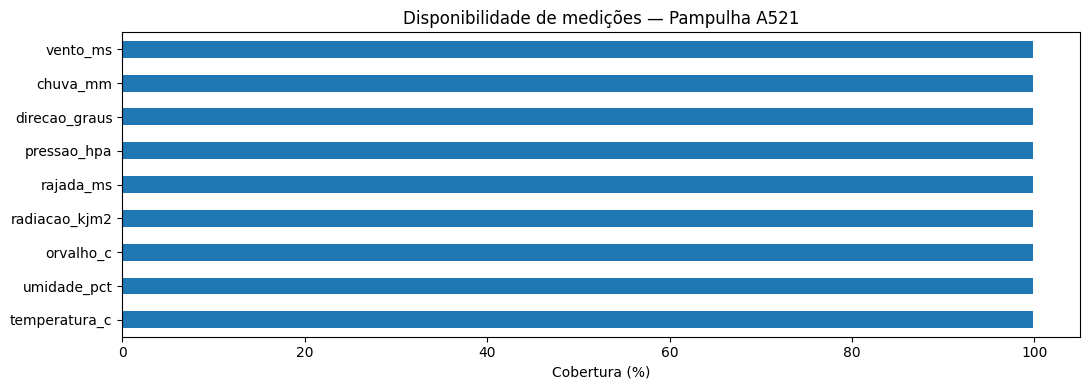

In [7]:
vars_meteo = ['chuva_mm','temperatura_c','umidade_pct','pressao_hpa','vento_ms','direcao_graus','rajada_ms','orvalho_c','radiacao_kjm2']
qualidade = pd.DataFrame({'presentes':limpo[vars_meteo].notna().sum(), 'ausentes':limpo[vars_meteo].isna().sum()})
qualidade['cobertura_pct'] = (100*qualidade['presentes']/len(limpo)).round(2)
display(qualidade.sort_values('cobertura_pct'))
fig,ax = plt.subplots(figsize=(11,4))
qualidade['cobertura_pct'].sort_values().plot.barh(ax=ax)
ax.set(xlabel='Cobertura (%)',title='Disponibilidade de medições — Pampulha A521',xlim=(0,105))
plt.tight_layout();plt.show()

##8. Precipitação diária: só somar dias com 24 horas válidas

Dias completos: 3994
Dias incompletos: 24


,chuva_total_mm,horas_validas,ano,mes
datetime_utc,,,,
2015-01-01 00:00:00+00:00,1.4,24,2015,1
2015-01-02 00:00:00+00:00,0.2,24,2015,1
2015-01-03 00:00:00+00:00,0.6,24,2015,1
2015-01-04 00:00:00+00:00,0.0,24,2015,1
2015-01-05 00:00:00+00:00,0.0,24,2015,1


Os totais anuais abaixo são parciais quando existem dias incompletos:


,dias_completos,chuva_somada_dias_completos_mm
ano,,
2015,363,1251.8
2016,364,1455.0
2017,361,1193.0
2018,364,1686.6
2019,365,1070.4
2020,359,2076.8
2021,365,1664.4
2022,363,1670.8
2023,365,1211.4


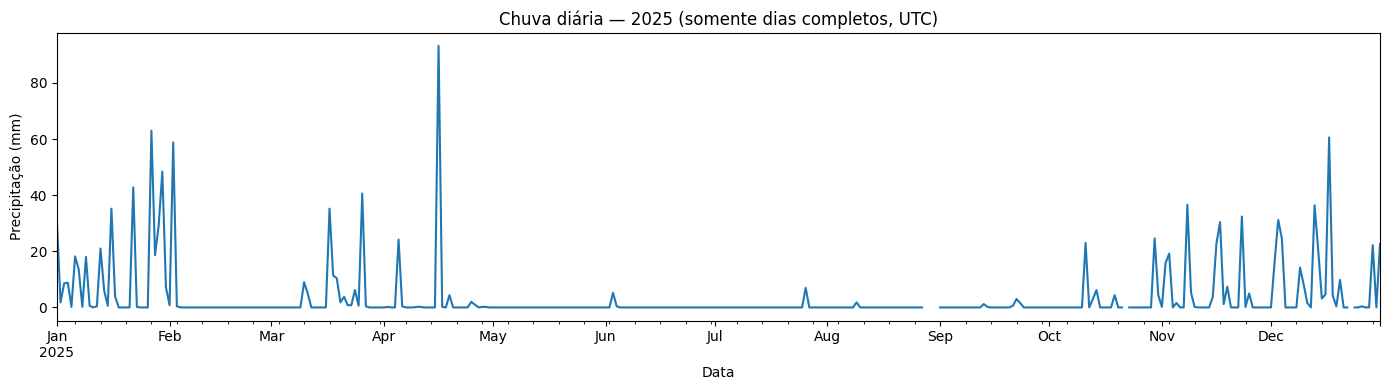

In [8]:
chuva_diaria = limpo['chuva_mm'].resample('D').agg(['sum','count'])
chuva_diaria = chuva_diaria.rename(columns={'sum':'chuva_total_mm','count':'horas_validas'})
chuva_diaria.loc[chuva_diaria['horas_validas'] < 24, 'chuva_total_mm'] = np.nan
chuva_diaria['ano'] = chuva_diaria.index.year
chuva_diaria['mes'] = chuva_diaria.index.month
print('Dias completos:', int(chuva_diaria['chuva_total_mm'].notna().sum()))
print('Dias incompletos:', int(chuva_diaria['chuva_total_mm'].isna().sum()))
display(chuva_diaria.head())

anual_dias = chuva_diaria.groupby('ano').agg(dias_completos=('chuva_total_mm','count'), chuva_somada_dias_completos_mm=('chuva_total_mm','sum'))
print('Os totais anuais abaixo são parciais quando existem dias incompletos:')
display(anual_dias.round(1))
fig,ax=plt.subplots(figsize=(14,4))
chuva_diaria.loc['2025','chuva_total_mm'].plot(ax=ax)
ax.set(title='Chuva diária — 2025 (somente dias completos, UTC)',ylabel='Precipitação (mm)',xlabel='Data')
plt.tight_layout();plt.show()

#Graficos de registro das chuvas MG-Pampulha BH

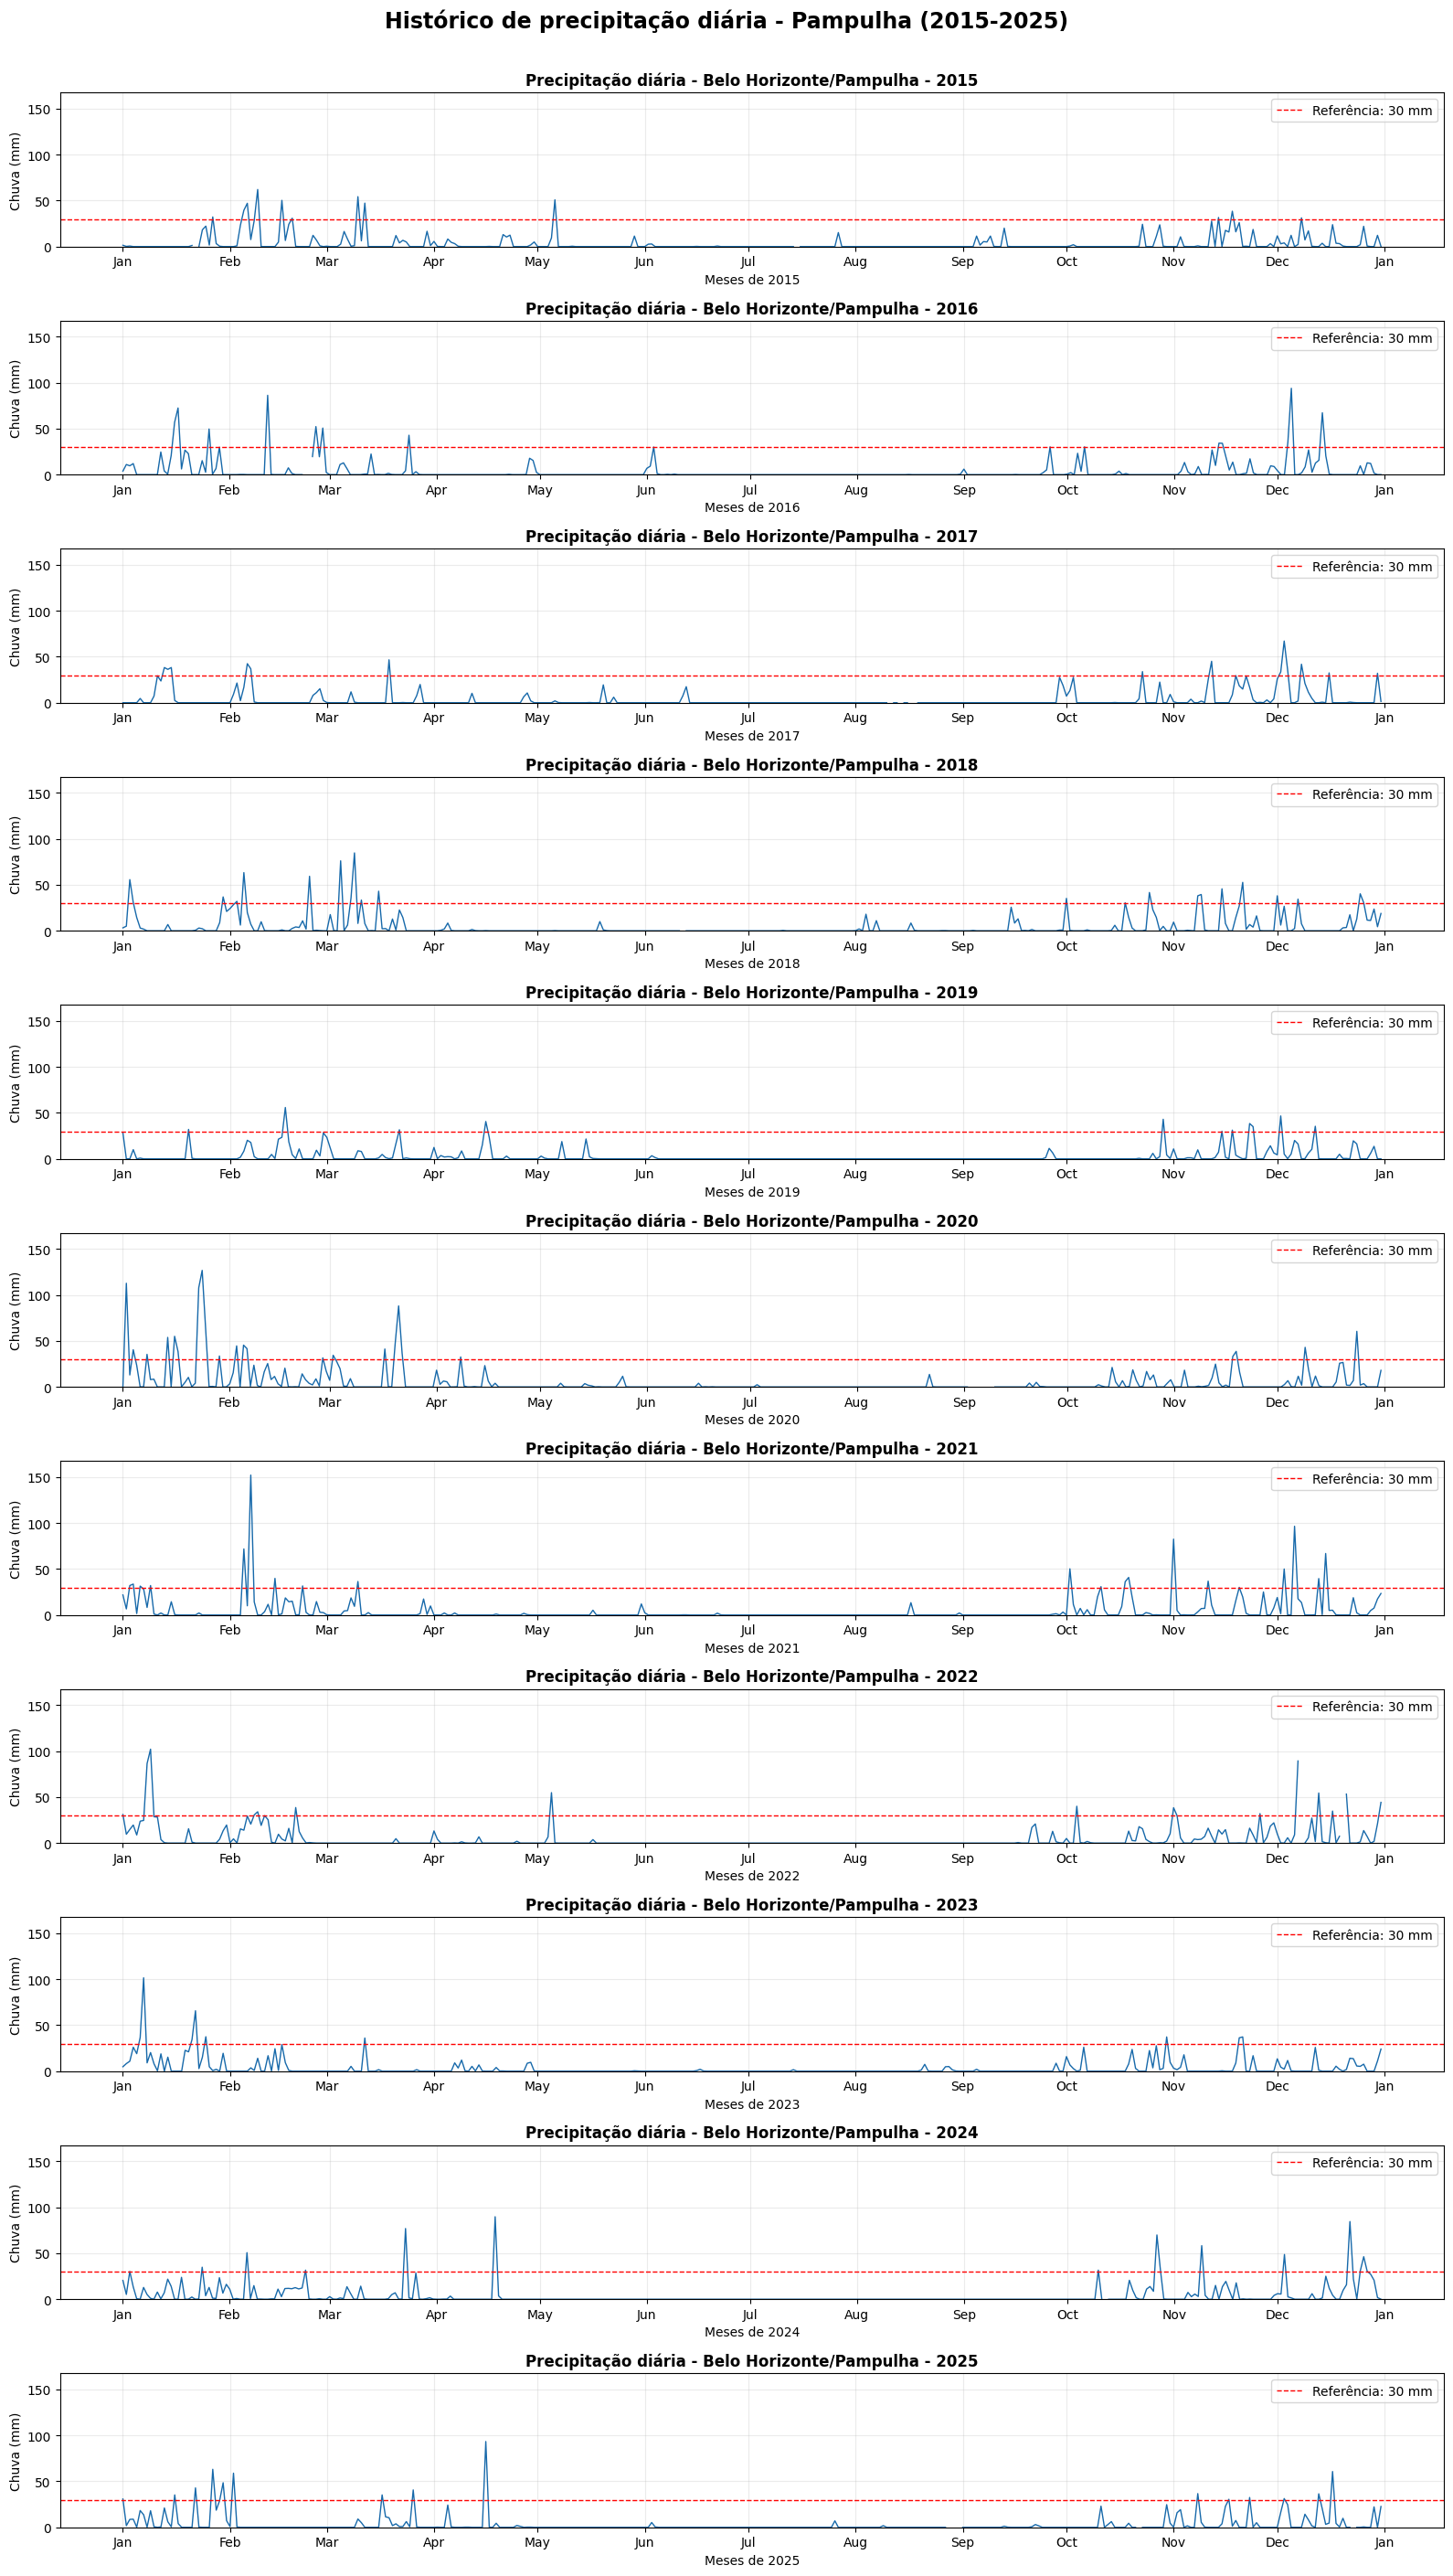

In [9]:

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Anos que serão analisados
anos = range(2015, 2026)

# Criar 11 gráficos, um para cada ano
fig, axes = plt.subplots(
    nrows=11,
    ncols=1,
    figsize=(16, 28),
    sharex=False,
    sharey=True
)

# Escala vertical igual para todos os anos
max_chuva = chuva_diaria["chuva_total_mm"].max()
limite_y = max(35, max_chuva * 1.10)

for i, ano in enumerate(anos):

    # Selecionar os dados do ano
    dados_ano = chuva_diaria.loc[
        chuva_diaria["ano"] == ano
    ]

    # Gráfico da precipitação diária
    axes[i].plot(
        dados_ano.index,
        dados_ano["chuva_total_mm"],
        color="#1769AA",
        linewidth=1
    )

    # Linha de referência de 30 mm
    axes[i].axhline(
        y=30,
        color="red",
        linestyle="--",
        linewidth=1,
        label="Referência: 30 mm"
    )

    axes[i].set_title(
        f"Precipitação diária - Belo Horizonte/Pampulha - {ano}",
        fontsize=12,
        fontweight="bold"
    )

    axes[i].set_ylabel("Chuva (mm)")
    axes[i].set_ylim(0, limite_y)

    # Exibir os meses no eixo horizontal
    axes[i].xaxis.set_major_locator(
        mdates.MonthLocator()
    )
    axes[i].xaxis.set_major_formatter(
        mdates.DateFormatter("%b")
    )

    axes[i].grid(alpha=0.25)
    axes[i].legend(loc="upper right")

    # Identificação do ano
    axes[i].set_xlabel(f"Meses de {ano}")

plt.suptitle(
    "Histórico de precipitação diária - Pampulha (2015-2025)",
    fontsize=17,
    fontweight="bold",
    y=1.005
)

plt.tight_layout()

# Salvar imagem no Google Drive
plt.savefig(
    "/content/drive/MyDrive/Dados_MG/"
    "graficos_chuvas_pampulha_2015_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


#9. Sazonalidade mensal e eventos observados de 30 mm em 24 horas


Exploração: avaliamos, nesta etapa, dias completos com chuva ≥ 30 mm. Esta é uma aproximação por dias UTC e não substitui a definição do alvo de previsão com janelas móveis de 24 horas, que será preparada no notebook 02.

,dias_validos,media_mm,eventos_30mm,frequencia_eventos_pct
mes,,,,
1,340,10.11,40,11.76
2,309,8.69,28,9.06
3,341,4.72,20,5.87
4,330,2.06,4,1.21
5,341,0.79,2,0.59
6,329,0.31,1,0.3
7,340,0.08,0,0.0
8,334,0.31,0,0.0
9,323,0.93,1,0.31


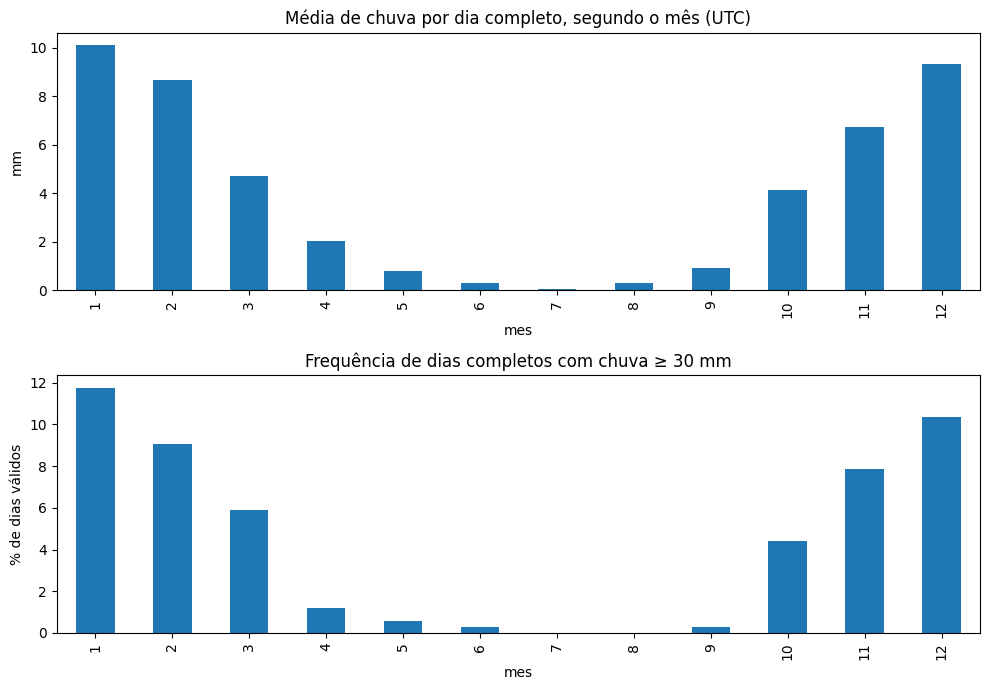

In [10]:
base_completa = chuva_diaria.dropna(subset=['chuva_total_mm']).copy()
base_completa['evento_diario_30mm'] = (base_completa['chuva_total_mm'] >= 30).astype(int)
mensal = base_completa.groupby('mes').agg(
    dias_validos=('chuva_total_mm','count'),
    media_mm=('chuva_total_mm','mean'),
    eventos_30mm=('evento_diario_30mm','sum')
)
mensal['frequencia_eventos_pct'] = (100*mensal['eventos_30mm']/mensal['dias_validos']).round(2)
display(mensal.round(2))
fig,axes=plt.subplots(2,1,figsize=(10,7))
mensal['media_mm'].plot.bar(ax=axes[0],title='Média de chuva por dia completo, segundo o mês (UTC)',ylabel='mm')
mensal['frequencia_eventos_pct'].plot.bar(ax=axes[1],title='Frequência de dias completos com chuva ≥ 30 mm',ylabel='% de dias válidos')
plt.tight_layout();plt.show()

#10. Auditoria das lacunas consecutivas em chuva

In [11]:
aus = limpo['chuva_mm'].isna()
grupos = (aus != aus.shift(fill_value=False)).cumsum()
lacunas = []
for _, pedaco in aus.groupby(grupos):
    if bool(pedaco.iloc[0]):
        lacunas.append({'inicio_utc':pedaco.index.min(),'fim_utc':pedaco.index.max(),'horas':len(pedaco)})
lacunas_df = pd.DataFrame(lacunas, columns=['inicio_utc','fim_utc','horas']).sort_values('horas', ascending=False)
print('Sequências de precipitação ausente:',len(lacunas_df))
display(lacunas_df.head(15))

Sequências de precipitação ausente: 24


,inicio_utc,fim_utc,horas
3,2016-02-23 18:00:00+00:00,2016-02-24 10:00:00+00:00,17
15,2020-09-08 20:00:00+00:00,2020-09-09 10:00:00+00:00,15
13,2020-09-06 21:00:00+00:00,2020-09-07 10:00:00+00:00,14
14,2020-09-07 21:00:00+00:00,2020-09-08 10:00:00+00:00,14
11,2020-09-04 21:00:00+00:00,2020-09-05 09:00:00+00:00,13
12,2020-09-05 21:00:00+00:00,2020-09-06 09:00:00+00:00,13
10,2020-09-03 22:00:00+00:00,2020-09-04 09:00:00+00:00,12
9,2020-09-03 02:00:00+00:00,2020-09-03 09:00:00+00:00,8
22,2025-10-22 16:00:00+00:00,2025-10-22 22:00:00+00:00,7
16,2022-12-08 03:00:00+00:00,2022-12-08 09:00:00+00:00,7


#11. Exportar os resultados para o Google Drive

In [12]:
import shutil
import zipfile
from pathlib import Path

try:
    from google.colab import drive  # apenas verifica que o ambiente é Colab
    pasta = Path('/content/drive/MyDrive/Resultados_Pampulha')
except ImportError:
    pasta = Path('resultados_pampulha')
pasta.mkdir(parents=True, exist_ok=True)

limpo.to_csv(pasta / 'pampulha_horario_limpo_2015_2025.csv', index=True)
resumo_anual.to_csv(pasta / 'resumo_anual_cobertura.csv')
qualidade.to_csv(pasta / 'qualidade_variaveis.csv')
chuva_diaria.to_csv(pasta / 'chuva_diaria_dias_completos.csv')
lacunas_df.to_csv(pasta / 'lacunas_precipitacao.csv', index=False)

print('Arquivos gerados:')
for arq in sorted(pasta.glob('*.csv')):
    print(' -', arq.name, f'({arq.stat().st_size/1024/1024:.2f} MB)')

# Criando o ZIP manualmente com suporte a Zip64 para evitar o erro de limite de tamanho
zip_caminho = pasta / 'resultados_pampulha.zip'
with zipfile.ZipFile(zip_caminho, 'w', zipfile.ZIP_DEFLATED, allowZip64=True) as zf:
    for arq in pasta.glob('*.csv'):
        zf.write(arq, arcname=arq.name)

print('ZIP de resultados gerado com sucesso com Zip64:', zip_caminho)

Arquivos gerados:
 - chuva_diaria_dias_completos.csv (0.16 MB)
 - lacunas_precipitacao.csv (0.00 MB)
 - pampulha_horario_limpo_2015_2025.csv (7.73 MB)
 - qualidade_variaveis.csv (0.00 MB)
 - resumo_anual_cobertura.csv (0.00 MB)
ZIP de resultados gerado com sucesso com Zip64: /content/drive/MyDrive/Resultados_Pampulha/resultados_pampulha.zip


#ETAPA 2
Janelas de 6/12/24 h, evento futuro ≥ 30 mm, divisão temporal e baseline
Localidade/estação: Belo Horizonte — Pampulha (INMET A521):

#1. Bibliotecas e parâmetros

In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             precision_recall_fscore_support, roc_auc_score)

pd.set_option('display.max_columns', 25)
ANO_INICIAL, ANO_FINAL = 2015, 2025
LIMIAR_CHUVA_MM = 30.0
HORIZONTE_H = 24
JANELAS_H = [6, 12, 24]
# Parâmetros fixos ANTES da leitura do teste
TREINO_FIM = pd.Timestamp('2022-01-01', tz='UTC')
VALIDACAO_FIM = pd.Timestamp('2024-01-01', tz='UTC')
FIM_EXCLUSIVO = pd.Timestamp('2026-01-01', tz='UTC')

print('Alvo: chuva acumulada nas horas t+1..t+24 >= 30 mm')
print('Treino: 2015–2021 | validação: 2022–2023 | teste: 2024–2025')

Alvo: chuva acumulada nas horas t+1..t+24 >= 30 mm
Treino: 2015–2021 | validação: 2022–2023 | teste: 2024–2025


#2. Montar Drive e ler a base limpa do Notebook 01

In [14]:
from pathlib import Path
import pandas as pd

pasta_01 = Path('/content/drive/MyDrive/Resultados_Pampulha')

arquivo = pasta_01 / 'pampulha_horario_limpo_2015_2025.csv'
if not arquivo.exists():
    raise FileNotFoundError(
        f'Arquivo não encontrado: {arquivo}. Execute a etapa de exportação do Notebook 01 '
        'e confirme o nome da pasta no Google Drive.'
    )

base = pd.read_csv(arquivo, low_memory=False)
if 'datetime_utc' not in base.columns or 'chuva_mm' not in base.columns:
    raise ValueError('Base incompatível: faltam datetime_utc ou chuva_mm.')
base['datetime_utc'] = pd.to_datetime(base['datetime_utc'], utc=True, errors='coerce')
if base['datetime_utc'].isna().any():
    raise ValueError('Há datas UTC não reconhecidas.')
if base['datetime_utc'].duplicated().any():
    raise ValueError('Existem horários duplicados: revisar Notebook 01 antes de continuar.')
base = base.set_index('datetime_utc').sort_index()
index_esperado = pd.date_range('2015-01-01', '2025-12-31 23:00', freq='h', tz='UTC')
if len(base) != len(index_esperado) or not base.index.equals(index_esperado):
    raise ValueError('A série não tem todas as horas esperadas de 2015 a 2025. Revisar Notebook 01.')
cols_numericas = ['chuva_mm', 'temperatura_c', 'umidade_pct', 'pressao_hpa',
                  'vento_ms', 'direcao_graus', 'rajada_ms', 'orvalho_c', 'radiacao_kjm2']
for coluna in cols_numericas:
    if coluna in base.columns:
        base[coluna] = pd.to_numeric(base[coluna], errors='coerce')
print(f'{len(base):,} horários; de {base.index.min()} até {base.index.max()}')
print(f'Chuva ausente: {base.chuva_mm.isna().sum():,} horas')
display(base.head(3))

96,432 horários; de 2015-01-01 00:00:00+00:00 até 2025-12-31 23:00:00+00:00
Chuva ausente: 141 horas


,data,hora,chuva_mm,temperatura_c,umidade_pct,pressao_hpa,vento_ms,direcao_graus,rajada_ms,orvalho_c,radiacao_kjm2
datetime_utc,,,,,,,,,,,
2015-01-01 00:00:00+00:00,2015-01-01,0,0.0,26.4,59.0,918.0,1.6,79.0,4.7,17.9,-3.3
2015-01-01 01:00:00+00:00,2015-01-01,100,0.0,26.1,61.0,918.9,2.3,78.0,5.1,17.9,-3.5
2015-01-01 02:00:00+00:00,2015-01-01,200,0.0,25.8,59.0,919.1,2.6,94.0,7.1,17.1,-3.5


#3. Variáveis retrospectivas (sem futuro)

In [15]:
dados = base.copy()
for horas in JANELAS_H:
    dados[f'chuva_passada_{horas}h_mm'] = (
        dados['chuva_mm'].rolling(window=horas, min_periods=horas).sum()
    )
    for var in ['temperatura_c', 'umidade_pct', 'pressao_hpa', 'vento_ms']:
        if var in dados.columns:
            dados[f'{var}_media_{horas}h'] = (
                dados[var].rolling(window=horas, min_periods=horas).mean()
            )
# Variáveis de calendário disponíveis no instante da previsão, em UTC
dados['mes_utc'] = dados.index.month
dados['hora_utc'] = dados.index.hour

print('Cobertura das janelas retrospectivas de chuva:')
display(pd.DataFrame({
    'janela_h': JANELAS_H,
    'validas': [int(dados[f'chuva_passada_{h}h_mm'].notna().sum()) for h in JANELAS_H],
    'incompletas': [int(dados[f'chuva_passada_{h}h_mm'].isna().sum()) for h in JANELAS_H]
}))

Cobertura das janelas retrospectivas de chuva:


,janela_h,validas,incompletas
0,6,96166,266
1,12,96023,409
2,24,95807,625


#4. Definir o evento-alvo Futuro (t+1 a t+24)

In [16]:
# Construção explícita evita dúvidas de alinhamento em rolling/shift.
chuva_futura = pd.concat(
    [dados['chuva_mm'].shift(-h).rename(f'h_mais_{h}')
     for h in range(1, HORIZONTE_H + 1)], axis=1
)
dados['horas_futuras_validas'] = chuva_futura.notna().sum(axis=1)
dados['chuva_proximas_24h_mm'] = chuva_futura.sum(axis=1, min_count=HORIZONTE_H)
dados['evento_30mm_proximas_24h'] = pd.Series(np.nan, index=dados.index)
mascara_alvo = dados['chuva_proximas_24h_mm'].notna()
dados.loc[mascara_alvo, 'evento_30mm_proximas_24h'] = (
    dados.loc[mascara_alvo, 'chuva_proximas_24h_mm'] >= LIMIAR_CHUVA_MM
).astype(int)

print('Horários com alvo válido:', int(mascara_alvo.sum()))
print('Horários com alvo incompleto:', int((~mascara_alvo).sum()))
print('Eventos positivos entre alvos válidos:', int(dados['evento_30mm_proximas_24h'].sum()))
display(dados[['chuva_mm','chuva_passada_24h_mm', 'chuva_proximas_24h_mm',
               'horas_futuras_validas', 'evento_30mm_proximas_24h']].head(28))

Horários com alvo válido: 95806
Horários com alvo incompleto: 626
Eventos positivos entre alvos válidos: 3938


,chuva_mm,chuva_passada_24h_mm,chuva_proximas_24h_mm,horas_futuras_validas,evento_30mm_proximas_24h
datetime_utc,,,,,
2015-01-01 00:00:00+00:00,0.0,NaN,1.4,24,0.0
2015-01-01 01:00:00+00:00,0.0,NaN,1.4,24,0.0
2015-01-01 02:00:00+00:00,0.0,NaN,1.4,24,0.0
2015-01-01 03:00:00+00:00,0.0,NaN,1.4,24,0.0
2015-01-01 04:00:00+00:00,0.0,NaN,1.4,24,0.0
2015-01-01 05:00:00+00:00,0.0,NaN,1.4,24,0.0
2015-01-01 06:00:00+00:00,0.0,NaN,1.4,24,0.0
2015-01-01 07:00:00+00:00,0.0,NaN,1.4,24,0.0
2015-01-01 08:00:00+00:00,0.0,NaN,1.4,24,0.0


#6. Selecionar linhas aptas e dividir cronologicamente
Usaremos apenas horários com 24 h de chuva passada válida e 24 h de chuva futura válida; isso inclui automaticamente as janelas retrospectivas de 6/12 h. O alvo de cada linha do treino precisa terminar antes do primeiro horário de validação, e o da validação precisa terminar antes do início do teste. Essa purga evita que resultados futuros atravessem conjuntos. Não há embaralhamento.

In [17]:
aptos = dados.loc[
    dados['chuva_passada_24h_mm'].notna()
    & dados['evento_30mm_proximas_24h'].notna()
].copy()
aptos['fim_janela_alvo_utc'] = aptos.index + pd.Timedelta(hours=24)

# A janela futura precisa estar integralmente contida no conjunto cronológico.
treino = aptos.loc[aptos['fim_janela_alvo_utc'] < TREINO_FIM].copy()
validacao = aptos.loc[
    (aptos.index >= TREINO_FIM)
    & (aptos['fim_janela_alvo_utc'] < VALIDACAO_FIM)
].copy()
teste = aptos.loc[
    (aptos.index >= VALIDACAO_FIM)
    & (aptos['fim_janela_alvo_utc'] < FIM_EXCLUSIVO)
].copy()

for nome, parte in [('Treino', treino), ('Validação', validacao), ('Teste', teste)]:
    print(f'{nome}: {len(parte):,} instantes; positivos: '
          f'{int(parte["evento_30mm_proximas_24h"].sum()):,} '
          f'({parte["evento_30mm_proximas_24h"].mean():.2%}); '
          f'intervalo {parte.index.min()} a {parte.index.max()}')
    if parte.empty or parte['evento_30mm_proximas_24h'].nunique() < 2:
        print('ATENÇÃO: conjunto vazio ou sem uma das classes. Revisar período e alvo.')
assert treino.index.max() < TREINO_FIM
assert treino['fim_janela_alvo_utc'].max() < TREINO_FIM
assert validacao.index.min() >= TREINO_FIM
assert validacao['fim_janela_alvo_utc'].max() < VALIDACAO_FIM
assert teste.index.min() >= VALIDACAO_FIM
assert not treino.index.intersection(validacao.index).size
assert not validacao.index.intersection(teste.index).size


Treino: 60,731 instantes; positivos: 2,668 (4.39%); intervalo 2015-01-01 23:00:00+00:00 a 2021-12-30 23:00:00+00:00
Validação: 17,394 instantes; positivos: 548 (3.15%); intervalo 2022-01-01 00:00:00+00:00 a 2023-12-30 23:00:00+00:00
Teste: 17,262 instantes; positivos: 689 (3.99%); intervalo 2024-01-01 00:00:00+00:00 a 2025-12-30 23:00:00+00:00


#7. Baseline probabilístico sazonal — frequência histórica por mês

In [18]:
resumo_mes = treino.groupby('mes_utc')['evento_30mm_proximas_24h'].agg(['sum','count'])
resumo_mes = resumo_mes.reindex(range(1,13), fill_value=0)
resumo_mes['probabilidade_baseline'] = (resumo_mes['sum']+1)/(resumo_mes['count']+2)
prob_global = (treino['evento_30mm_proximas_24h'].sum()+1)/(len(treino)+2)

def prever_baseline(parte):
    return parte['mes_utc'].map(resumo_mes['probabilidade_baseline']).fillna(prob_global).to_numpy(dtype=float)

p_treino = prever_baseline(treino)
p_val = prever_baseline(validacao)
p_teste = prever_baseline(teste)
print('Frequência global suavizada do treino:', f'{prob_global:.2%}')
display(resumo_mes.rename(columns={'sum':'eventos_treino','count':'registros_treino'}))

Frequência global suavizada do treino: 4.39%


,eventos_treino,registros_treino,probabilidade_baseline
mes_utc,,,
1,522.0,5137,0.101771
2,562.0,4674,0.120402
3,390.0,5208,0.075048
4,57.0,5040,0.011503
5,24.0,5208,0.004798
6,13.0,4992,0.002803
7,0.0,5159,0.000194
8,0.0,5041,0.000198
9,23.0,4840,0.004957


#8. Escolher limiar usando SOMENTE a validação

O baseline fornece probabilidades, não classes. Para apresentar recall/precision/F1 e matriz de confusão, escolhemos o limiar no conjunto de validação, maximizando F1. Não alteramos o limiar olhando o conjunto de teste. Para eventos raros, a classificação com limiar 0,50 pode ser inadequada; por isso a escolha explícita é importante.

In [19]:
y_treino = treino['evento_30mm_proximas_24h'].astype(int).to_numpy()
y_val = validacao['evento_30mm_proximas_24h'].astype(int).to_numpy()
y_teste = teste['evento_30mm_proximas_24h'].astype(int).to_numpy()

limiares = np.unique(np.r_[0.0, np.linspace(0.01, 0.99, 99), p_val, 1.0])
registros = []
for corte in limiares:
    predito = (p_val >= corte).astype(int)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_val, predito, average='binary', zero_division=0)
    registros.append((corte, precision, recall, f1))
limiares_df = pd.DataFrame(registros, columns=['limiar','precision','recall','f1'])
# Desempate estável: priorizar maior recall e depois menor limiar
melhor = limiares_df.sort_values(
    ['f1','recall','limiar'], ascending=[False,False,True]
).iloc[0]
LIMIAR_CLASSIFICACAO = float(melhor['limiar'])
print(f'Limiar escolhido APENAS na validação: {LIMIAR_CLASSIFICACAO:.4f}')
display(melhor.to_frame('melhor_validacao'))

Limiar escolhido APENAS na validação: 0.0900


,melhor_validacao
limiar,0.090000
precision,0.108051
recall,0.558394
f1,0.181065


#9. Avaliar o baseline nos três períodos (teste reservado)

In [20]:
def metricas(nome, y, prob, corte):
    classes = (prob >= corte).astype(int)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y, classes, average='binary', zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y, classes, labels=[0,1]).ravel()
    ap = average_precision_score(y, prob) if y.sum() > 0 else np.nan
    roc = roc_auc_score(y, prob) if len(np.unique(y)) == 2 else np.nan
    return dict(conjunto=nome, linhas=len(y), eventos=int(y.sum()), frequencia_evento=y.mean(),
                brier=brier_score_loss(y,prob), average_precision_AP=ap, roc_auc=roc,
                precision=precision, recall=recall, f1=f1,
                TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp))

avaliacao = pd.DataFrame([
    metricas('treino',y_treino,p_treino,LIMIAR_CLASSIFICACAO),
    metricas('validacao',y_val,p_val,LIMIAR_CLASSIFICACAO),
    metricas('teste',y_teste,p_teste,LIMIAR_CLASSIFICACAO),
])
display(avaliacao.round(4))
print('Nota: as 24 janelas móveis em horas adjacentes podem descrever um mesmo episódio.')
print('Por isso, as métricas medem previsões horárias, não eventos independentes.')

,conjunto,linhas,eventos,frequencia_evento,brier,average_precision_AP,roc_auc,precision,recall,f1,TN,FP,FN,TP
0,treino,60731,2668,0.0439,0.0401,0.1022,0.7824,0.1105,0.4063,0.1737,49336,8727,1584,1084
1,validacao,17394,548,0.0315,0.0296,0.0857,0.7978,0.1081,0.5584,0.1811,14320,2526,242,306
2,teste,17262,689,0.0399,0.0371,0.0821,0.7649,0.0823,0.3411,0.1326,13952,2621,454,235


Nota: as 24 janelas móveis em horas adjacentes podem descrever um mesmo episódio.
Por isso, as métricas medem previsões horárias, não eventos independentes.


#10. Gráficos: frequência mensal aprendida e probabilidades no teste

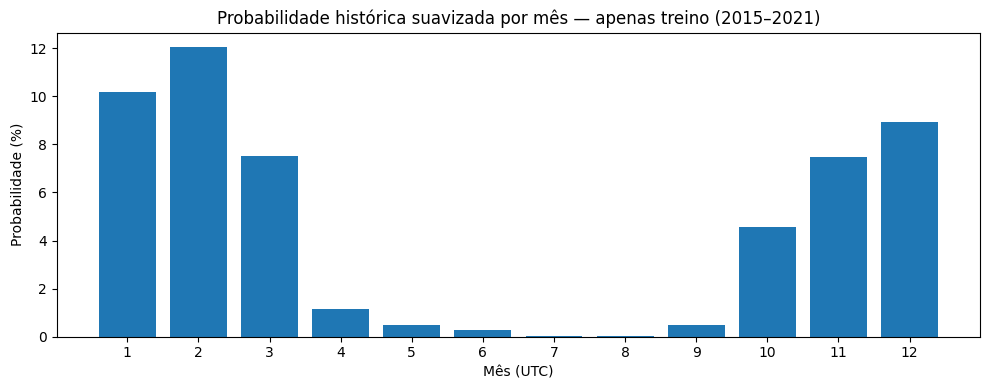

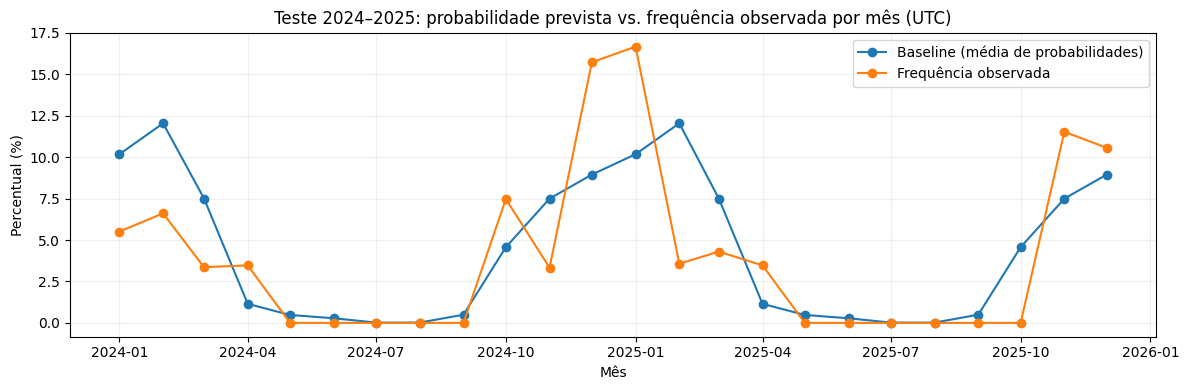

In [21]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(resumo_mes.index, 100*resumo_mes['probabilidade_baseline'])
ax.set(title='Probabilidade histórica suavizada por mês — apenas treino (2015–2021)',
       xlabel='Mês (UTC)', ylabel='Probabilidade (%)', xticks=range(1,13))
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
serie_prob = pd.Series(p_teste, index=teste.index).resample('MS').mean()
serie_obs = teste['evento_30mm_proximas_24h'].resample('MS').mean()
ax.plot(serie_prob.index, 100*serie_prob, marker='o', label='Baseline (média de probabilidades)')
ax.plot(serie_obs.index, 100*serie_obs, marker='o', label='Frequência observada')
ax.set(title='Teste 2024–2025: probabilidade prevista vs. frequência observada por mês (UTC)',
       ylabel='Percentual (%)', xlabel='Mês')
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

#Complementar - Graficos

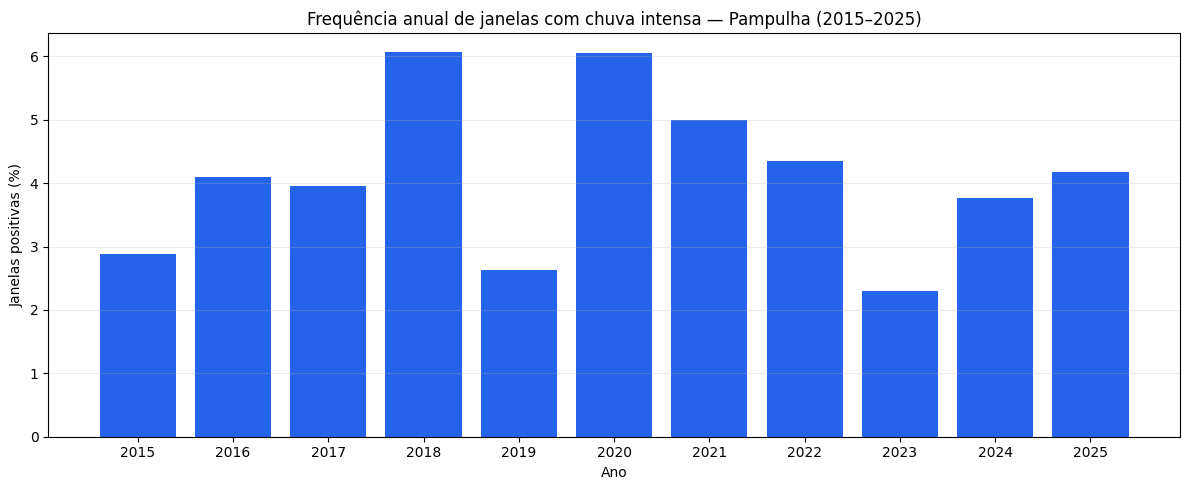

In [22]:

import matplotlib.pyplot as plt

# Utilizar todos os registros com alvo válido
historico = dados.dropna(
    subset=['evento_30mm_proximas_24h']
).copy()

# Calcular a frequência observada por ano
frequencia_anual = (
    historico
    .groupby(historico.index.year)
    ['evento_30mm_proximas_24h']
    .mean() * 100
)

# Gerar gráfico
fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    frequencia_anual.index,
    frequencia_anual.values,
    color='#2563eb'
)

ax.set_title(
    'Frequência anual de janelas com chuva intensa — Pampulha (2015–2025)'
)
ax.set_xlabel('Ano')
ax.set_ylabel('Janelas positivas (%)')
ax.set_xticks(range(2015, 2026))
ax.grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()


#11. Exportação e documentação da metodologia
Exportei apenas os dados aptos e o diagnóstico. Importante: o CSV de modelagem contém o rótulo futuro e o acumulado futuro para auditoria; em uma aplicação real essas colunas não podem ser fornecidas ao modelo como entradas. Para modelos supervisionados posteriores, usar somente colunas retrospectivas e calendário. Os índices UTC são preservados.

In [23]:
saida = pasta_01 / 'Notebook_02'
saida.mkdir(parents=True, exist_ok=True)

cols_explicativas = [f'chuva_passada_{h}h_mm' for h in JANELAS_H]
cols_explicativas += [f'{v}_media_{h}h'
                      for h in JANELAS_H
                      for v in ['temperatura_c','umidade_pct','pressao_hpa','vento_ms']
                      if f'{v}_media_{h}h' in aptos.columns]
cols_explicativas += ['mes_utc','hora_utc']
cols_auditoria = ['chuva_proximas_24h_mm','horas_futuras_validas',
                  'evento_30mm_proximas_24h', 'fim_janela_alvo_utc']
colunas_exportar = cols_explicativas + cols_auditoria

for nome, parte, prob in [('treino',treino,p_treino),('validacao',validacao,p_val),('teste',teste,p_teste)]:
    result = parte[colunas_exportar].copy()
    result['prob_baseline_mes'] = prob
    result.to_csv(saida / f'{nome}_pampulha.csv', index_label='datetime_utc')

avaliacao.to_csv(saida / 'metricas_baseline.csv',index=False)
resumo_mes.to_csv(saida / 'baseline_frequencia_mensal_treino.csv',index_label='mes_utc')
limiares_df.to_csv(saida / 'limiares_avaliados_na_validacao.csv',index=False)

relatorio = f"""MeteoPredict BH | Notebook 02
Estação: Pampulha A521; horário UTC; período 2015-2025.
Objetivo: chuva >= {LIMIAR_CHUVA_MM} mm nas próximas {HORIZONTE_H} horas (t+1 a t+24).
Janelas retrospectivas: {JANELAS_H} horas (incluindo a hora t).
Janelas incompletas: excluídas; faltantes não imputados como zero.
Divisão: treino 2015-2021, validação 2022-2023, teste 2024-2025.
Purga: alvo futuro inteiramente anterior à fronteira seguinte.
Baseline: frequência mensal treinada exclusivamente em 2015-2021, Laplace alpha=1.
Limiar: {LIMIAR_CLASSIFICACAO:.5f}, otimizado somente na validação por F1.
Treino n={len(treino)}, validação n={len(validacao)}, teste n={len(teste)}.
Nota: janelas futuras sobrepostas não são eventos meteorológicos independentes.
Nota: X = apenas colunas retrospectivas + calendário; não incluir chuva_proximas_24h_mm no modelo.
"""
(saida / 'metodologia_notebook_02.txt').write_text(relatorio, encoding='utf-8')
print('Arquivos salvos em:', saida)
for path in sorted(saida.iterdir()): print(' •', path.name)


Arquivos salvos em: /content/drive/MyDrive/Resultados_Pampulha/Notebook_02
 • baseline_frequencia_mensal_treino.csv
 • limiares_avaliados_na_validacao.csv
 • metodologia_notebook_02.txt
 • metricas_baseline.csv
 • teste_pampulha.csv
 • treino_pampulha.csv
 • validacao_pampulha.csv


#ETAPA 3

#1. Bibliotecas e configurações

In [24]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, brier_score_loss,
    confusion_matrix, precision_recall_fscore_support, roc_auc_score,
    precision_recall_curve, PrecisionRecallDisplay)
import joblib

SEMENTE = 42
np.random.seed(SEMENTE)
USAR_XGBOOST = True  # Se indisponível, o notebook segue com dois modelos.
LIMIAR_CHUVA_MM = 30
print('Notebook 03 iniciado — ajuste somente no treino e escolha pela validação.')

Notebook 03 iniciado — ajuste somente no treino e escolha pela validação.


#2. Montar o Drive e carregar as exportações do Notebook 02

In [25]:
from pathlib import Path
import pandas as pd

PASTA = Path('/content/drive/MyDrive/Resultados_Pampulha/Notebook_02')

SAIDA = PASTA.parent / 'Notebook_03'
SAIDA.mkdir(parents=True, exist_ok=True)
ARQUIVOS = {'treino': 'treino_pampulha.csv',
           'validacao': 'validacao_pampulha.csv',
           'teste': 'teste_pampulha.csv'}
for nome, arq in ARQUIVOS.items():
    if not (PASTA / arq).exists():
        raise FileNotFoundError(f'Falta {PASTA / arq}. Execute a exportação do Notebook 02.')

def ler(nome):
    df = pd.read_csv(PASTA / ARQUIVOS[nome], low_memory=False)
    if 'datetime_utc' not in df or 'evento_30mm_proximas_24h' not in df:
        raise ValueError(f'{nome}: colunas essenciais ausentes.')
    df['datetime_utc'] = pd.to_datetime(df['datetime_utc'], utc=True, errors='raise')
    df = df.set_index('datetime_utc').sort_index()
    if df.index.has_duplicates: raise ValueError(f'{nome}: datas duplicadas.')
    return df

treino, validacao, teste = (ler(x) for x in ['treino','validacao','teste'])
for nome, df in [('Treino', treino), ('Validação', validacao), ('Teste', teste)]:
    print(f'{nome}: {len(df):,} horas; positivos={int(df.evento_30mm_proximas_24h.sum()):,} '
          f'({df.evento_30mm_proximas_24h.mean():.2%})')
assert treino.index.max() < validacao.index.min() < teste.index.min()
assert treino.index.max().year <= 2021
assert validacao.index.min().year == 2022 and validacao.index.max().year <= 2023
assert teste.index.min().year == 2024 and teste.index.max().year <= 2025
for df in (treino, validacao, teste):
    fim = pd.to_datetime(df['fim_janela_alvo_utc'], utc=True)
    assert (fim == df.index + pd.Timedelta(hours=24)).all()
assert pd.to_datetime(treino['fim_janela_alvo_utc'], utc=True).max() < validacao.index.min()
assert pd.to_datetime(validacao['fim_janela_alvo_utc'], utc=True).max() < teste.index.min()
print('Checagens cronológicas concluídas.')

Treino: 60,731 horas; positivos=2,668 (4.39%)
Validação: 17,394 horas; positivos=548 (3.15%)
Teste: 17,262 horas; positivos=689 (3.99%)
Checagens cronológicas concluídas.


#3. Seleção explícita de variáveis — nenhuma variável futura entra no modelo

In [26]:
JANELAS = [6, 12, 24]
VARIAVEIS = [f'chuva_passada_{h}h_mm' for h in JANELAS]
for v in ['temperatura_c','umidade_pct','pressao_hpa','vento_ms']:
    VARIAVEIS += [f'{v}_media_{h}h' for h in JANELAS]
VARIAVEIS += ['mes_utc','hora_utc']

PROIBIDAS = {'chuva_proximas_24h_mm','horas_futuras_validas',
    'evento_30mm_proximas_24h','fim_janela_alvo_utc','prob_baseline_mes'}
assert not (set(VARIAVEIS) & PROIBIDAS)
for nome, df in [('treino',treino), ('validacao',validacao), ('teste',teste)]:
    faltando = set(VARIAVEIS) - set(df.columns)
    if faltando: raise ValueError(f'{nome}: variáveis faltantes: {sorted(faltando)}')

X_tr = treino[VARIAVEIS].apply(pd.to_numeric, errors='coerce')
X_val = validacao[VARIAVEIS].apply(pd.to_numeric, errors='coerce')
X_te = teste[VARIAVEIS].apply(pd.to_numeric, errors='coerce')
y_tr = treino['evento_30mm_proximas_24h'].astype(int).to_numpy()
y_val = validacao['evento_30mm_proximas_24h'].astype(int).to_numpy()
y_te = teste['evento_30mm_proximas_24h'].astype(int).to_numpy()
assert set(np.unique(y_tr)) == {0, 1} and set(np.unique(y_val)) == {0, 1}
assert set(np.unique(y_te)) == {0, 1}
print(f'{len(VARIAVEIS)} preditores:')
print(VARIAVEIS)
display(pd.DataFrame({'ausentes_treino': X_tr.isna().sum(),
                      'pct_ausente_treino': X_tr.isna().mean().mul(100)}).round(2))

17 preditores:
['chuva_passada_6h_mm', 'chuva_passada_12h_mm', 'chuva_passada_24h_mm', 'temperatura_c_media_6h', 'temperatura_c_media_12h', 'temperatura_c_media_24h', 'umidade_pct_media_6h', 'umidade_pct_media_12h', 'umidade_pct_media_24h', 'pressao_hpa_media_6h', 'pressao_hpa_media_12h', 'pressao_hpa_media_24h', 'vento_ms_media_6h', 'vento_ms_media_12h', 'vento_ms_media_24h', 'mes_utc', 'hora_utc']


,ausentes_treino,pct_ausente_treino
chuva_passada_6h_mm,0,0.0
chuva_passada_12h_mm,0,0.0
chuva_passada_24h_mm,0,0.0
temperatura_c_media_6h,0,0.0
temperatura_c_media_12h,0,0.0
temperatura_c_media_24h,0,0.0
umidade_pct_media_6h,0,0.0
umidade_pct_media_12h,0,0.0
umidade_pct_media_24h,0,0.0
pressao_hpa_media_6h,0,0.0


#4. Métricas e otimização de limiar
Usaremos Average Precision (AP), Brier Score, ROC-AUC, precisão, recall e F1. O limiar de classificação é escolhido maximizando o F1 apenas na validação, conforme Notebook 02. As probabilidades são avaliadas sem depender do limiar; o baseline também será avaliado com seu próprio limiar definido anteriormente.

In [27]:
def selecionar_limiar(y, prob):
    # Método vetorizado: testa todos os cortes únicos sem loops custosos.
    precisao, recall, cortes = precision_recall_curve(y, prob)
    f1 = np.divide(2 * precisao[:-1] * recall[:-1],
                   precisao[:-1] + recall[:-1],
                   out=np.zeros_like(precisao[:-1]),
                   where=(precisao[:-1] + recall[:-1]) > 0)
    candidatos = pd.DataFrame({'limiar': cortes, 'precisao':precisao[:-1],
                               'recall':recall[:-1], 'f1':f1})
    return candidatos.sort_values(['f1','recall','limiar'],
                                  ascending=[False,False,True]).iloc[0].to_dict()

def avaliar(nome, conjunto, y, prob, limiar):
    pred = (prob >= limiar).astype(int)
    pr, re, f1, _ = precision_recall_fscore_support(
        y, pred, average='binary', zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y,pred,labels=[0,1]).ravel()
    return {'modelo':nome,'conjunto':conjunto,'linhas':len(y),
            'positivos':int(y.sum()),'frequencia_positivos':float(y.mean()),
            'limiar':float(limiar),'precision':float(pr),'recall':float(re),
            'f1':float(f1),'AP':float(average_precision_score(y,prob)),
            'roc_auc':float(roc_auc_score(y,prob)),
            'brier':float(brier_score_loss(y,prob)),
            'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)}

#5. Regressão logística — imputação e escala ajustadas exclusivamente no treino

In [28]:
config_log = [0.1, 1.0, 10.0]
resultados_val = []
modelos = {}
for c in config_log:
    nome = f'Logistica_C{c:g}'
    pipe = Pipeline([
        ('imputer',SimpleImputer(strategy='median', add_indicator=False)),
        ('scaler',StandardScaler()),
        ('modelo',LogisticRegression(C=c, max_iter=500, random_state=SEMENTE))
    ])
    pipe.fit(X_tr, y_tr)
    p = pipe.predict_proba(X_val)[:,1]
    corte = selecionar_limiar(y_val,p)
    registro = avaliar(nome,'validacao',y_val,p,corte['limiar'])
    resultados_val.append(registro)
    modelos[nome] = pipe
    print(nome, 'AP=',round(registro['AP'],4), 'F1=',round(registro['f1'],4))

Logistica_C0.1 AP= 0.2015 F1= 0.3105
Logistica_C1 AP= 0.1955 F1= 0.307
Logistica_C10 AP= 0.1922 F1= 0.3036


#6. Random Forest — imputação ajustada exclusivamente no treino

In [29]:
config_rf = [{'n_estimators':150,'max_depth':8,'min_samples_leaf':15},
             {'n_estimators':150,'max_depth':12,'min_samples_leaf':30}]
for cfg in config_rf:
    nome = f"RandomForest_d{cfg['max_depth']}_leaf{cfg['min_samples_leaf']}"
    pipe = Pipeline([
        ('imputer',SimpleImputer(strategy='median')),
        ('modelo',RandomForestClassifier(**cfg, n_jobs=-1, random_state=SEMENTE))
    ])
    pipe.fit(X_tr,y_tr)
    p = pipe.predict_proba(X_val)[:,1]
    corte = selecionar_limiar(y_val,p)
    registro = avaliar(nome,'validacao',y_val,p,corte['limiar'])
    resultados_val.append(registro)
    modelos[nome] = pipe
    print(nome, 'AP=',round(registro['AP'],4), 'F1=',round(registro['f1'],4))

RandomForest_d8_leaf15 AP= 0.2361 F1= 0.3204
RandomForest_d12_leaf30 AP= 0.2112 F1= 0.3233


#7. XGBoost opcional (se a biblioteca estiver disponível)

In [30]:
if USAR_XGBOOST:
    try:
        from xgboost import XGBClassifier
        for depth, estim in [(3,180),(5,180)]:
            nome = f'XGBoost_d{depth}_n{estim}'
            pipe = Pipeline([
                ('imputer',SimpleImputer(strategy='median')),
                ('modelo',XGBClassifier(n_estimators=estim, max_depth=depth,
                    learning_rate=0.05, subsample=0.85,
                    colsample_bytree=0.9, objective='binary:logistic',
                    eval_metric='logloss', tree_method='hist',
                    random_state=SEMENTE, n_jobs=2))
            ])
            pipe.fit(X_tr,y_tr)
            p = pipe.predict_proba(X_val)[:,1]
            corte = selecionar_limiar(y_val,p)
            registro = avaliar(nome,'validacao',y_val,p,corte['limiar'])
            resultados_val.append(registro)
            modelos[nome] = pipe
            print(nome, 'AP=',round(registro['AP'],4),'F1=',round(registro['f1'],4))
    except ImportError:
        print('XGBoost não instalado: os dois modelos obrigatórios continuam disponíveis.')

XGBoost_d3_n180 AP= 0.264 F1= 0.3392
XGBoost_d5_n180 AP= 0.2544 F1= 0.3131


#8. Seleção final somente pela validação
Critério principal pré-definido: maior AP (útil para eventos raros). Empates: menor Brier e maior F1. O limiar de cada configuração já foi definido na validação. Não usar o teste para escolher qual modelo será vencedor.

In [31]:
comparacao_val = pd.DataFrame(resultados_val).sort_values(
    ['AP','brier','f1'], ascending=[False,True,False]).reset_index(drop=True)
display(comparacao_val[['modelo','AP','brier','roc_auc','precision','recall','f1','limiar']].round(4))
VENCEDOR = str(comparacao_val.loc[0,'modelo'])
LIMIAR_ESCOLHIDO = float(comparacao_val.loc[0,'limiar'])
MODELO_ESCOLHIDO = modelos[VENCEDOR]
print('Escolhido pela validação:',VENCEDOR,'| limiar:',round(LIMIAR_ESCOLHIDO,5))
comparacao_val.to_csv(SAIDA/'comparacao_modelos_validacao.csv',index=False)

,modelo,AP,brier,roc_auc,precision,recall,f1,limiar
0,XGBoost_d3_n180,0.2640,0.0275,0.8611,0.3467,0.3321,0.3392,0.2502
1,XGBoost_d5_n180,0.2544,0.0279,0.8576,0.2517,0.4142,0.3131,0.2193
2,RandomForest_d8_leaf15,0.2361,0.0276,0.8703,0.2782,0.3777,0.3204,0.2049
3,RandomForest_d12_leaf30,0.2112,0.0281,0.8630,0.2622,0.4215,0.3233,0.2071
4,Logistica_C0.1,0.2015,0.0277,0.8739,0.2358,0.4544,0.3105,0.1750
5,Logistica_C1,0.1955,0.0278,0.8724,0.2261,0.4781,0.3070,0.1654
6,Logistica_C10,0.1922,0.0279,0.8716,0.2186,0.4964,0.3036,0.1572


Escolhido pela validação: XGBoost_d3_n180 | limiar: 0.25022


#9. Avaliação Final do modelo escolhido em teste — uma única passagem

In [32]:
p_val_final = MODELO_ESCOLHIDO.predict_proba(X_val)[:,1]
p_teste_final = MODELO_ESCOLHIDO.predict_proba(X_te)[:,1]
metricas_final = pd.DataFrame([
    avaliar(VENCEDOR,'validacao',y_val,p_val_final,LIMIAR_ESCOLHIDO),
    avaliar(VENCEDOR,'teste',y_te,p_teste_final,LIMIAR_ESCOLHIDO)
])
display(metricas_final.round(4))
metricas_final.to_csv(SAIDA/'metricas_modelo_escolhido.csv',index=False)

# Baseline sazonal congelado do Notebook 02: sem recalcular suas probabilidades.
arq_base = PASTA / 'metricas_baseline.csv'
if arq_base.exists():
    baseline_metricas = pd.read_csv(arq_base)
    print('Métricas originais do baseline (Notebook 02):')
    display(baseline_metricas.round(4))
else:
    print('Arquivo de métricas do baseline não encontrado.')

if 'prob_baseline_mes' in teste.columns:
    p_base = pd.to_numeric(teste['prob_baseline_mes'],errors='coerce').to_numpy()
    assert np.isfinite(p_base).all()
    print('Teste: AP do baseline =',round(average_precision_score(y_te,p_base),4),
          '| AP do modelo escolhido =',round(average_precision_score(y_te,p_teste_final),4))

,modelo,conjunto,linhas,positivos,frequencia_positivos,limiar,precision,recall,f1,AP,roc_auc,brier,TN,FP,FN,TP
0,XGBoost_d3_n180,validacao,17394,548,0.0315,0.2502,0.3467,0.3321,0.3392,0.2640,0.8611,0.0275,16503,343,366,182
1,XGBoost_d3_n180,teste,17262,689,0.0399,0.2502,0.0926,0.0435,0.0592,0.1131,0.8279,0.0372,16279,294,659,30


Métricas originais do baseline (Notebook 02):


,conjunto,linhas,eventos,frequencia_evento,brier,average_precision_AP,roc_auc,precision,recall,f1,TN,FP,FN,TP
0,treino,60731,2668,0.0439,0.0401,0.1022,0.7824,0.1105,0.4063,0.1737,49336,8727,1584,1084
1,validacao,17394,548,0.0315,0.0296,0.0857,0.7978,0.1081,0.5584,0.1811,14320,2526,242,306
2,teste,17262,689,0.0399,0.0371,0.0821,0.7649,0.0823,0.3411,0.1326,13952,2621,454,235


Teste: AP do baseline = 0.0821 | AP do modelo escolhido = 0.1131


#10. Visualizações e matriz de confusão no teste

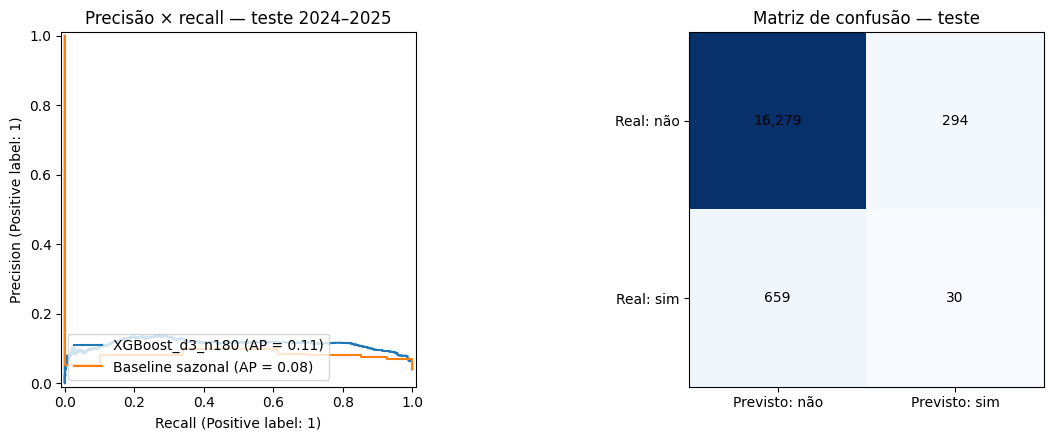

,importancia
chuva_passada_24h_mm,0.181815
pressao_hpa_media_12h,0.153752
pressao_hpa_media_24h,0.151164
mes_utc,0.070976
pressao_hpa_media_6h,0.062706
chuva_passada_6h_mm,0.046619
vento_ms_media_12h,0.045565
chuva_passada_12h_mm,0.044318
umidade_pct_media_24h,0.044297
umidade_pct_media_12h,0.036089


In [33]:
fig, axs = plt.subplots(1,2,figsize=(13,4.5))
PrecisionRecallDisplay.from_predictions(y_te,p_teste_final,name=VENCEDOR,ax=axs[0])
if 'prob_baseline_mes' in teste.columns:
    PrecisionRecallDisplay.from_predictions(y_te,p_base,name='Baseline sazonal',ax=axs[0])
axs[0].set_title('Precisão × recall — teste 2024–2025')
cm = confusion_matrix(y_te, (p_teste_final>=LIMIAR_ESCOLHIDO).astype(int), labels=[0,1])
axs[1].imshow(cm,cmap='Blues')
for (i,j),v in np.ndenumerate(cm):
    axs[1].text(j,i,f'{v:,}',ha='center',va='center',color='black')
axs[1].set_xticks([0,1],['Previsto: não','Previsto: sim'])
axs[1].set_yticks([0,1],['Real: não','Real: sim'])
axs[1].set_title('Matriz de confusão — teste')
plt.tight_layout()
plt.savefig(SAIDA/'curva_PR_e_matriz_teste.png',dpi=180,bbox_inches='tight')
plt.show()

# Importância permutativa sem tocar no período de teste: opcional em amostra de validação.
importancias = None
if hasattr(MODELO_ESCOLHIDO.named_steps['modelo'],'feature_importances_'):
    importancias = pd.Series(MODELO_ESCOLHIDO.named_steps['modelo'].feature_importances_,index=VARIAVEIS).sort_values(ascending=False)
    display(importancias.head(12).to_frame('importancia'))
    importancias.to_csv(SAIDA/'importancias_modelo.csv',header=['importancia'])

#11. Salvar modelo, variáveis, previsões e resumo metodológico

In [34]:
joblib.dump(MODELO_ESCOLHIDO, SAIDA/'modelo_selecionado_pampulha.joblib')
pd.DataFrame({'datetime_utc':teste.index.astype(str),
              'observado':y_te,
              'probabilidade_modelo':p_teste_final,
              'classe_prevista':(p_teste_final>=LIMIAR_ESCOLHIDO).astype(int),
              'probabilidade_baseline':p_base if 'prob_baseline_mes' in teste.columns else np.nan
             }).to_csv(SAIDA/'previsoes_teste_modelo_escolhido.csv',index=False)
metadados = {
    'estacao':'Pampulha A521','periodo':'2015–2025',
    'treino':'2015–2021','validacao':'2022–2023','teste':'2024–2025',
    'limiar_evento_mm':LIMIAR_CHUVA_MM,'horizonte_h':24,
    'modelo_selecionado':VENCEDOR,'limiar_classificacao':LIMIAR_ESCOLHIDO,
    'preditores':VARIAVEIS,'selecao':'maior AP na validacao; empate menor Brier e maior F1',
    'observacao':'Previsões horárias de uma estação; janelas sobrepostas não são eventos independentes.'
}
(SAIDA/'metodologia_modelo.json').write_text(json.dumps(metadados,indent=2,ensure_ascii=False),encoding='utf-8')
print('Arquivos exportados em:',SAIDA)
print('\nNotebook 03 concluído. Não retreinar/alterar o modelo após observar o teste sem nova avaliação independente.')

Arquivos exportados em: /content/drive/MyDrive/Resultados_Pampulha/Notebook_03

Notebook 03 concluído. Não retreinar/alterar o modelo após observar o teste sem nova avaliação independente.


#ETAPA 4



#1. Preparação e ligação ao Google Drive

In [35]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (average_precision_score, brier_score_loss,
                             precision_recall_fscore_support, confusion_matrix,
                             roc_auc_score, precision_recall_curve)
from IPython.display import display

RAIZ = Path('/content/drive/MyDrive/Resultados_Pampulha')

DIR2 = RAIZ / 'Notebook_02'
DIR3 = RAIZ / 'Notebook_03'
SAIDA = RAIZ / 'Notebook_04'
SAIDA.mkdir(parents=True, exist_ok=True)
print('Pasta de saída:', SAIDA)


Pasta de saída: /content/drive/MyDrive/Resultados_Pampulha/Notebook_04


#2. Carregar arquivos congelados e conferir identidade das linhas
Usamos as probabilidades já exportadas pelo Notebook 03; nenhum modelo será ajustado nesta etapa. Identificamos divergências entre arquivos para não misturar execuções.

In [36]:
ARQUIVOS = [DIR3/'previsoes_teste_modelo_escolhido.csv',
            DIR3/'metricas_modelo_escolhido.csv', DIR2/'metricas_baseline.csv',
            DIR2/'teste_pampulha.csv', DIR3/'metodologia_modelo.json']
for f in ARQUIVOS:
    if not f.exists():
        raise FileNotFoundError(f'Arquivo necessário não encontrado: {f}. Execute as exportações dos notebooks 02 e 03.')
previsoes = pd.read_csv(ARQUIVOS[0], parse_dates=['datetime_utc']).set_index('datetime_utc').sort_index()
metricas3 = pd.read_csv(ARQUIVOS[1])
metricas2 = pd.read_csv(ARQUIVOS[2])
teste = pd.read_csv(ARQUIVOS[3], parse_dates=['datetime_utc']).set_index('datetime_utc').sort_index()
meta = json.loads(ARQUIVOS[4].read_text(encoding='utf-8'))
assert not previsoes.index.has_duplicates and not teste.index.has_duplicates
assert previsoes.index.equals(teste.index), 'Os arquivos de teste e previsão têm índices diferentes. Não misture execuções.'
assert np.array_equal(previsoes['observado'].to_numpy(dtype=int),
                      teste['evento_30mm_proximas_24h'].to_numpy(dtype=int)), 'Alvos divergentes entre os arquivos.'
assert len(previsoes)==17262, 'Quantidade diferente da execução de referência; revisar arquivos.'
for c in ['observado','probabilidade_modelo','probabilidade_baseline','classe_prevista']:
    assert previsoes[c].notna().all(), f'Valores ausentes: {c}'
for c in ['probabilidade_modelo','probabilidade_baseline']:
    assert previsoes[c].between(0,1).all(), f'Probabilidade fora de [0,1]: {c}'
print('Modelo:',meta['modelo_selecionado'])
print('Limiar informado no arquivo de metodologia:',meta['limiar_classificacao'])
print('Observações:',len(previsoes),'| positivos:',int(previsoes.observado.sum()))
display(previsoes.head(3))


Modelo: XGBoost_d3_n180
Limiar informado no arquivo de metodologia: 0.25021985173225403
Observações: 17262 | positivos: 689


,observado,probabilidade_modelo,classe_prevista,probabilidade_baseline
datetime_utc,,,,
2024-01-01 00:00:00+00:00,0,0.223564,0,0.101771
2024-01-01 01:00:00+00:00,0,0.194352,0,0.101771
2024-01-01 02:00:00+00:00,0,0.192483,0,0.101771


#3. Integridade do limiar e das classes previstas
Esta célula não busca um limiar melhor. Verifica apenas se os arquivos salvos correspondem à mesma execução. Caso haja diferença, interrompe o uso da matriz binária e solicita reexportação do Notebook 03.

In [37]:
LIMIAR = float(meta['limiar_classificacao'])
y = previsoes['observado'].to_numpy(dtype=int)
p_modelo = previsoes['probabilidade_modelo'].to_numpy(dtype=float)
p_base = previsoes['probabilidade_baseline'].to_numpy(dtype=float)
classes_salvas = previsoes['classe_prevista'].to_numpy(dtype=int)
classes_reconst = (p_modelo >= LIMIAR).astype(int)
concordam = np.array_equal(classes_salvas, classes_reconst)
print('Previsões binárias consistentes com limiar salvo?',concordam)
if not concordam:
    divergentes = int((classes_salvas != classes_reconst).sum())
    raise ValueError(f'{divergentes} classificações incompatíveis com o limiar do JSON. '
                     'Reexecute a exportação do Notebook 03 e use arquivos da mesma execução.')
print('Limiar congelado confirmado:',round(LIMIAR,6))


Previsões binárias consistentes com limiar salvo? True
Limiar congelado confirmado: 0.25022


#4. Comparação no mesmo conjunto de teste


In [38]:
def metricas_prob(y, p):
    return {'AP':average_precision_score(y,p),'Brier':brier_score_loss(y,p),
            'ROC_AUC':roc_auc_score(y,p)}
def metricas_bin(y,p,corte):
    pred=(p>=corte).astype(int)
    pr,rc,f1,_=precision_recall_fscore_support(y,pred,average='binary',zero_division=0)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return {'precisao':pr,'recall':rc,'F1':f1,'TN':tn,'FP':fp,'FN':fn,'TP':tp}
base_teste=metricas2.loc[metricas2['conjunto'].eq('teste')].iloc[0]
resultado=[{'modelo':'Baseline sazonal (corte fixado no Notebook 02)',
            'AP':float(base_teste['average_precision_AP']), 'Brier':float(base_teste['brier']),
            'ROC_AUC':float(base_teste['roc_auc']),
            'precisao':float(base_teste['precision']), 'recall':float(base_teste['recall']),
            'F1':float(base_teste['f1'])},
           {'modelo':meta['modelo_selecionado'],**metricas_prob(y,p_modelo),
            **{k:v for k,v in metricas_bin(y,p_modelo,LIMIAR).items() if k in ['precisao','recall','F1']}}]
comparacao=pd.DataFrame(resultado).set_index('modelo')
display(comparacao.round(4))
comparacao.to_csv(SAIDA/'comparacao_baseline_modelo_teste.csv')
print('AP do baseline recalculado das probabilidades:',round(average_precision_score(y,p_base),4))
print('AP do baseline no Notebook 02:',round(float(base_teste['average_precision_AP']),4))
assert abs(average_precision_score(y,p_base)-float(base_teste['average_precision_AP'])) < 1e-8, 'Baseline não coincide com a exportação original.'


,AP,Brier,ROC_AUC,precisao,recall,F1
modelo,,,,,,
Baseline sazonal (corte fixado no Notebook 02),0.0821,0.0371,0.7649,0.0823,0.3411,0.1326
XGBoost_d3_n180,0.1131,0.0372,0.8279,0.0926,0.0435,0.0592


AP do baseline recalculado das probabilidades: 0.0821
AP do baseline no Notebook 02: 0.0821


#5. Diagnóstico anual: 2024 x 2025
Não há seleção de modelos por ano; apenas verificamos se o desempenho varia entre os dois anos reservados para teste.

,ano,modelo,horas,positivas,frequencia_positivas,AP,Brier,precisao,recall,F1,TN,FP,FN,TP
0,2024,XGBoost selecionado,8736,330,0.0378,0.0989,0.0360,0.0987,0.0455,0.0622,8269.0,137.0,315.0,15.0
1,2024,Baseline sazonal,8736,330,0.0378,0.0768,0.0355,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2025,XGBoost selecionado,8526,359,0.0421,0.1315,0.0385,0.0872,0.0418,0.0565,8010.0,157.0,344.0,15.0
3,2025,Baseline sazonal,8526,359,0.0421,0.0939,0.0387,NaN,NaN,NaN,NaN,NaN,NaN,NaN


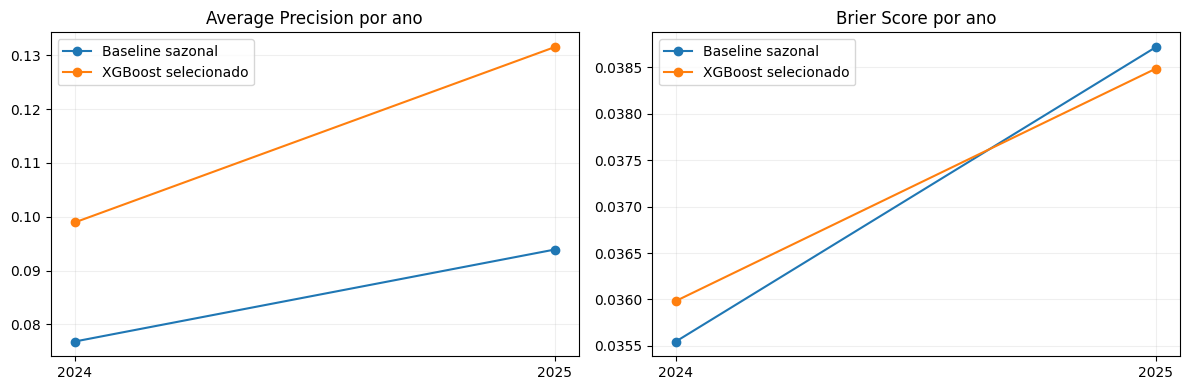

In [39]:
linhas=[]
for ano,grupo in previsoes.groupby(previsoes.index.year):
    yy=grupo['observado'].to_numpy(dtype=int)
    pm=grupo['probabilidade_modelo'].to_numpy(dtype=float)
    pb=grupo['probabilidade_baseline'].to_numpy(dtype=float)
    for nome,pp in [('XGBoost selecionado',pm),('Baseline sazonal',pb)]:
        r={'ano':int(ano),'modelo':nome,'horas':len(yy),'positivas':int(yy.sum()),
           'frequencia_positivas':float(yy.mean()), 'AP':average_precision_score(yy,pp),
           'Brier':brier_score_loss(yy,pp)}
        if nome=='XGBoost selecionado':r.update(metricas_bin(yy,pp,LIMIAR))
        linhas.append(r)
anual=pd.DataFrame(linhas)
display(anual.round(4))
anual.to_csv(SAIDA/'diagnostico_por_ano.csv',index=False)
fig,axs=plt.subplots(1,2,figsize=(12,4))
for nome,parte in anual.groupby('modelo'):
    axs[0].plot(parte.ano,parte.AP,marker='o',label=nome)
    axs[1].plot(parte.ano,parte.Brier,marker='o',label=nome)
for ax,t in zip(axs,['Average Precision por ano','Brier Score por ano']):
    ax.set_title(t);ax.set_xticks([2024,2025]);ax.grid(alpha=.2);ax.legend()
plt.tight_layout();plt.savefig(SAIDA/'comparacao_anual.png',dpi=180);plt.show()


#6. Diagrama de confiabilidade — descritivo, sem recalibrar o modelo
Cada faixa de probabilidade compara a previsão média com a taxa observada. Faixas com poucos registros são sinalizadas.

,faixa,n,previsto,observado,modelo
0,"(-0.001, 0.1]",14376,0.0183,0.0245,XGBoost selecionado
1,"(0.1, 0.2]",2197,0.1423,0.1188,XGBoost selecionado
2,"(0.2, 0.3]",558,0.2387,0.1183,XGBoost selecionado
3,"(0.3, 0.4]",117,0.3354,0.0855,XGBoost selecionado
4,"(0.4, 0.5]",13,0.4300,0.0000,XGBoost selecionado
5,"(0.5, 0.6]",1,0.5138,0.0000,XGBoost selecionado
10,"(-0.001, 0.1]",14406,0.0309,0.0315,Baseline sazonal
11,"(0.1, 0.2]",2856,0.1107,0.0823,Baseline sazonal


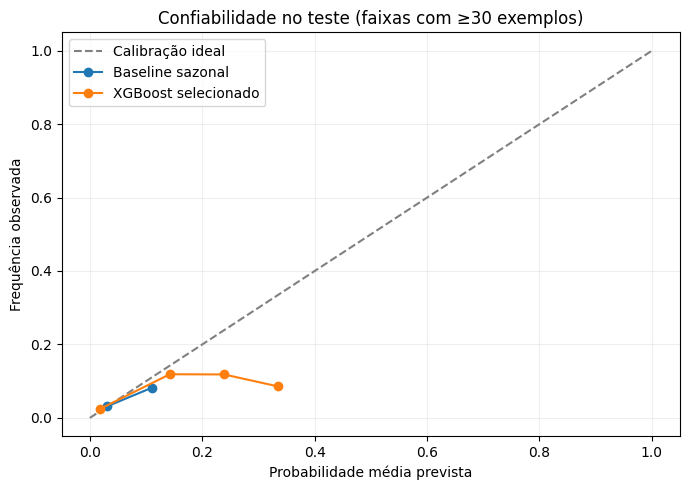

In [40]:
faixas=np.linspace(0,1,11)
reli=[]
for nome,p in [('XGBoost selecionado',p_modelo),('Baseline sazonal',p_base)]:
    grupos=pd.DataFrame({'p':p,'y':y,'faixa':pd.cut(p,faixas,include_lowest=True)})
    tabela=grupos.groupby('faixa',observed=False).agg(n=('y','size'),previsto=('p','mean'),observado=('y','mean')).reset_index()
    tabela['modelo']=nome
    reli.append(tabela)
reli=pd.concat(reli,ignore_index=True)
display(reli.loc[reli.n.gt(0)].round(4))
reli.to_csv(SAIDA/'calibracao_descritiva_faixas.csv',index=False)
fig,ax=plt.subplots(figsize=(7,5))
ax.plot([0,1],[0,1],'--',color='gray',label='Calibração ideal')
for nome,g in reli.loc[reli.n.ge(30)].groupby('modelo'):
    ax.plot(g.previsto,g.observado,'o-',label=nome)
ax.set(xlabel='Probabilidade média prevista',ylabel='Frequência observada',title='Confiabilidade no teste (faixas com ≥30 exemplos)')
ax.legend();ax.grid(alpha=.2);plt.tight_layout()
plt.savefig(SAIDA/'calibracao_descritiva.png',dpi=180);plt.show()


#7. Diagnóstico dos falsos negativos
Analisa quando o classificador deixou de indicar janelas positivas, mantendo o limiar original congelado.

In [41]:
analise=previsoes.copy()
analise['predito']=(analise.probabilidade_modelo>=LIMIAR).astype(int)
analise['categoria']=np.select([(analise.observado==1)&(analise.predito==1),
                               (analise.observado==1)&(analise.predito==0),
                               (analise.observado==0)&(analise.predito==1)],
                              ['TP','FN','FP'],default='TN')
analise['ano']=analise.index.year
analise['mes']=analise.index.month
matriz=analise.groupby(['ano','categoria']).size().unstack(fill_value=0)
display(matriz)
mensal=analise.groupby(['ano','mes','categoria']).size().unstack(fill_value=0).reset_index()
display(mensal.head(12))
mensal.to_csv(SAIDA/'erros_por_mes.csv',index=False)


categoria,FN,FP,TN,TP
ano,,,,
2024,315,137,8269,15
2025,344,157,8010,15


categoria,ano,mes,FN,FP,TN,TP
0,2024,1,30,69,634,11
1,2024,2,43,41,609,3
2,2024,3,25,19,700,0
3,2024,4,25,0,695,0
4,2024,5,0,0,744,0
5,2024,6,0,0,720,0
6,2024,7,0,0,744,0
7,2024,8,0,0,744,0
8,2024,9,0,0,720,0
9,2024,10,52,0,644,0


#8. Episódios sobrepostos — análise exploratória


In [42]:
positivos=analise.loc[analise.observado.eq(1)].copy()
# Nova sequência quando há intervalo maior do que uma hora entre instantes positivos.
novo=(positivos.index.to_series().diff()!=pd.Timedelta(hours=1))
positivos['id_sequencia']=novo.cumsum().to_numpy()
episodios=positivos.groupby('id_sequencia').agg(
    inicio=('ano',lambda x: x.index.min()),fim=('ano',lambda x:x.index.max()),
    janelas=('observado','size'),janelas_detectadas=('predito','sum'),
    maior_probabilidade=('probabilidade_modelo','max'))
episodios['detectado_alguma_vez']=episodios.janelas_detectadas.gt(0)
display(episodios.head(10))
print('Sequências positivas:',len(episodios))
print('Sequências com pelo menos uma janela sinalizada:',int(episodios.detectado_alguma_vez.sum()))
print('Taxa descritiva de sequências detectadas:',f'{episodios.detectado_alguma_vez.mean():.2%}')
episodios.to_csv(SAIDA/'episodios_janelas_positivas.csv')


,inicio,fim,janelas,janelas_detectadas,maior_probabilidade,detectado_alguma_vez
id_sequencia,,,,,,
1,2024-01-02 17:00:00+00:00,2024-01-02 21:00:00+00:00,5,0,0.228274,False
2,2024-01-02 23:00:00+00:00,2024-01-03 11:00:00+00:00,13,11,0.352652,True
3,2024-01-23 01:00:00+00:00,2024-01-23 23:00:00+00:00,23,0,0.199658,False
4,2024-02-05 19:00:00+00:00,2024-02-06 18:00:00+00:00,24,0,0.119252,False
5,2024-02-22 11:00:00+00:00,2024-02-23 08:00:00+00:00,22,3,0.294553,True
6,2024-03-22 03:00:00+00:00,2024-03-23 03:00:00+00:00,25,0,0.210495,False
7,2024-04-17 19:00:00+00:00,2024-04-18 19:00:00+00:00,25,0,0.083264,False
8,2024-10-09 20:00:00+00:00,2024-10-09 23:00:00+00:00,4,0,0.011038,False
9,2024-10-26 00:00:00+00:00,2024-10-26 23:00:00+00:00,24,0,0.120656,False


Sequências positivas: 34
Sequências com pelo menos uma janela sinalizada: 7
Taxa descritiva de sequências detectadas: 20.59%


#9. Conferências e exportação final
Registra o diagnóstico sem atualizar o modelo. Para um estudo futuro de calibração, os métodos precisam ser ajustados na validação ou em partição própria, com nova avaliação independente. Para transferência ao Cercadinho, é necessário construir as mesmas variáveis naquela estação, sem fazer médias entre pluviômetros.

In [43]:
resumo={
    'estacao':'Pampulha A521',
    'modelo':meta['modelo_selecionado'],
    'limiar_congelado':LIMIAR,
    'periodo_teste':'2024-2025',
    'registros_teste':int(len(y)),
    'positivos_teste':int(y.sum()),
    'comparacao_teste':comparacao.reset_index().to_dict(orient='records'),
    'episodios_definicao':'sequencias contiguas de janelas horarias positivas; nao temporais independentes',
    'numero_sequencias':int(len(episodios)),
    'numero_sequencias_detectadas':int(episodios.detectado_alguma_vez.sum()),
    'nota':'analise pos-teste descritiva; nenhuma escolha de modelo ou limiar pelo teste'
}
(SAIDA/'resumo_diagnostico.json').write_text(json.dumps(resumo,indent=2,ensure_ascii=False),encoding='utf-8')
print('Arquivos gerados em:',SAIDA)
for arq in sorted(SAIDA.glob('*')): print('-',arq.name)
print('Não foram alterados os arquivos dos notebooks 02 e 03.')


Arquivos gerados em: /content/drive/MyDrive/Resultados_Pampulha/Notebook_04
- calibracao_descritiva.png
- calibracao_descritiva_faixas.csv
- comparacao_anual.png
- comparacao_baseline_modelo_teste.csv
- diagnostico_por_ano.csv
- episodios_janelas_positivas.csv
- erros_por_mes.csv
- resumo_diagnostico.json
Não foram alterados os arquivos dos notebooks 02 e 03.


#ETAPA 5


#. Preparação e conexão ao Google Drive
Execute esta célula, mesmo que a pasta do Drive já apareça na lateral do Colab: a montagem na interface e a montagem em Python podem ser diferentes.

In [44]:
from pathlib import Path

RAIZ = Path('/content/drive/MyDrive/Resultados_Pampulha')
DIR3 = RAIZ / 'Notebook_03'
DIR4 = RAIZ / 'Notebook_04'
SAIDA = RAIZ / 'Notebook_05'
SAIDA.mkdir(parents=True, exist_ok=True)
print('Saída:', SAIDA)


Saída: /content/drive/MyDrive/Resultados_Pampulha/Notebook_05


In [45]:
#teste
import json
from pathlib import Path
import numpy as np
import pandas as pd

# Garante que os caminhos estejam definidos se a célula anterior não tiver sido executada
if 'DIR3' not in globals():
    RAIZ = Path('/content/drive/MyDrive/Resultados_Pampulha')
    DIR3 = RAIZ / 'Notebook_03'
    DIR4 = RAIZ / 'Notebook_04'

arq_pred = DIR3 / 'previsoes_teste_modelo_escolhido.csv'
arq_meta = DIR3 / 'metodologia_modelo.json'
for arquivo in (arq_pred, arq_meta):
    if not arquivo.exists():
        raise FileNotFoundError(f'Arquivo necessário não encontrado: {arquivo}')
meta = json.loads(arq_meta.read_text(encoding='utf-8'))
previsoes = pd.read_csv(arq_pred, parse_dates=['datetime_utc']).sort_values('datetime_utc')
previsoes['datetime_utc'] = pd.to_datetime(previsoes['datetime_utc'], utc=True)
necessarias = ['observado', 'probabilidade_modelo', 'probabilidade_baseline', 'classe_prevista']
assert not previsoes['datetime_utc'].duplicated().any(), 'Datas duplicadas.'
assert previsoes[necessarias].notna().all().all(), 'Campos essenciais incompletos.'
assert previsoes[['probabilidade_modelo', 'probabilidade_baseline']].apply(lambda s:s.between(0,1).all()).all()
limiar = float(meta['limiar_classificacao'])
classes = (previsoes['probabilidade_modelo'].to_numpy() >= limiar).astype(int)
assert np.array_equal(classes,previsoes['classe_prevista'].astype(int).to_numpy()), 'Limiar não corresponde às classes exportadas.'
assert previsoes['observado'].isin([0,1]).all()
print('Modelo:', meta['modelo_selecionado'])
print('Limiar validado:', limiar)
print('Registros:', len(previsoes), '| positivos:', int(previsoes['observado'].sum()))
print('Arquivos coerentes. Nenhuma nova seleção de limiar será efetuada.')

Modelo: XGBoost_d3_n180
Limiar validado: 0.25021985173225403
Registros: 17262 | positivos: 689
Arquivos coerentes. Nenhuma nova seleção de limiar será efetuada.


In [46]:
%pip -q install streamlit plotly scikit-learn

In [47]:
APP_CODE = 'import json\nfrom pathlib import Path\nimport numpy as np\nimport pandas as pd\nimport streamlit as st\nimport plotly.express as px\nfrom sklearn.metrics import average_precision_score, brier_score_loss, confusion_matrix, precision_recall_fscore_support\n\nst.set_page_config(page_title=\'MeteoPredict BH | Pampulha\', page_icon=\'🌧️\', layout=\'wide\')\nROOT = Path(\'/content/drive/MyDrive/Resultados_Pampulha\')\nDIR3 = ROOT / \'Notebook_03\'\nPATH_P = DIR3 / \'previsoes_teste_modelo_escolhido.csv\'\nPATH_M = DIR3 / \'metodologia_modelo.json\'\n\n@st.cache_data(show_spinner=False)\ndef carregar():\n    p = pd.read_csv(PATH_P, parse_dates=[\'datetime_utc\'])\n    m = json.loads(PATH_M.read_text(encoding=\'utf-8\'))\n    p[\'datetime_utc\'] = pd.to_datetime(p[\'datetime_utc\'], utc=True)\n    p = p.sort_values(\'datetime_utc\')\n    if p[\'datetime_utc\'].duplicated().any():\n        raise ValueError(\'Horários duplicados no CSV.\')\n    required = [\'observado\',\'probabilidade_modelo\',\'probabilidade_baseline\',\'classe_prevista\']\n    if not set(required).issubset(p.columns) or p[required].isna().any().any():\n        raise ValueError(\'Campos essenciais ausentes ou incompletos.\')\n    if not (p[[\'probabilidade_modelo\',\'probabilidade_baseline\']].ge(0).all().all() and\n            p[[\'probabilidade_modelo\',\'probabilidade_baseline\']].le(1).all().all()):\n        raise ValueError(\'Probabilidades fora de [0,1].\')\n    limiar = float(m[\'limiar_classificacao\'])\n    recomputadas = (p[\'probabilidade_modelo\'].to_numpy() >= limiar).astype(int)\n    if not np.array_equal(recomputadas, p[\'classe_prevista\'].astype(int).to_numpy()):\n        raise ValueError(\'O limiar do JSON NÃO corresponde às classes salvas. Reexportar Notebook 03; não alterar corte aqui.\')\n    p[\'local\'] = p[\'datetime_utc\'].dt.tz_convert(\'America/Sao_Paulo\')\n    return p,m\n\nst.title(\'🌧️ MeteoPredict BH\')\nst.caption(\'Protótipo acadêmico · Estação Pampulha A521 · Teste histórico 2024–2025 · Dados observacionais do INMET\')\nst.warning(\'Demonstração retrospectiva, NÃO é previsão em tempo real nem alerta oficial. O desempenho de detecção de chuvas intensas foi baixo no teste. Não representa toda Belo Horizonte.\')\ntry:\n    df, meta = carregar()\nexcept Exception as ex:\n    st.error(f\'Falha de integridade/importação: {ex}\')\n    st.stop()\nlimiar = float(meta[\'limiar_classificacao\'])\nst.sidebar.header(\'Filtros da análise histórica\')\nanos = sorted(df[\'local\'].dt.year.unique().tolist())\nanos_escolhidos = st.sidebar.multiselect(\'Anos (horário de Belo Horizonte)\', anos, default=anos)\nsub = df[df[\'local\'].dt.year.isin(anos_escolhidos)].copy()\nif sub.empty:\n    st.info(\'Selecione pelo menos um ano.\'); st.stop()\nsub[\'mes_local\'] = sub[\'local\'].dt.to_period(\'M\').astype(str)\nsub[\'predito\'] = (sub[\'probabilidade_modelo\']>=limiar).astype(int)\ny = sub[\'observado\'].astype(int).to_numpy()\npr = sub[\'predito\'].to_numpy()\npre, rec, f1, _ = precision_recall_fscore_support(y,pr,average=\'binary\',zero_division=0)\nap = average_precision_score(y,sub[\'probabilidade_modelo\']) if np.unique(y).size>1 else float(\'nan\')\nvalores = [(\'Registros horários\',f\'{len(sub):,}\'.replace(\',\',\'.\')),(\'Janelas positivas reais\',f\'{int(y.sum()):,}\'.replace(\',\',\'.\')),(\'AP XGBoost\', f\'{ap:.4f}\'),(\'Recall no filtro\',f\'{rec:.1%}\'),(\'Precisão no filtro\',f\'{pre:.1%}\')]\ncols=st.columns(5)\nfor col,(label,value) in zip(cols,valores): col.metric(label,value)\nst.caption(f"Modelo congelado: {meta[\'modelo_selecionado\']} · Limiar congelado da validação: {limiar:.5f} · Alvo: ≥ 30 mm nas próximas 24 h · Instantes exibidos em horário de Belo Horizonte (UTC−3).")\n\nst.subheader(\'Probabilidade média e frequência observada por mês\')\nmensal=sub.groupby(\'mes_local\').agg(prob_modelo=(\'probabilidade_modelo\',\'mean\'),prob_baseline=(\'probabilidade_baseline\',\'mean\'),observado=(\'observado\',\'mean\'),n=(\'observado\',\'size\')).reset_index()\nlong=mensal.melt(id_vars=\'mes_local\',value_vars=[\'prob_modelo\',\'prob_baseline\',\'observado\'],var_name=\'Série\',value_name=\'Proporção\')\nfig=px.line(long,x=\'mes_local\',y=\'Proporção\',color=\'Série\',markers=True)\nfig.update_layout(xaxis_title=\'Mês (horário local)\',yaxis_title=\'Proporção / probabilidade\',yaxis_tickformat=\'.0%\')\nst.plotly_chart(fig,use_container_width=True)\nst.caption(\'As curvas agregam janelas horárias sobrepostas; não são números de tempestades independentes. As probabilidades não foram recalibradas.\')\n\nc1,c2=st.columns(2)\nwith c1:\n    st.subheader(\'Matriz de confusão\')\n    mat=confusion_matrix(y,pr,labels=[0,1])\n    conf=pd.DataFrame(mat,index=[\'Real: não\',\'Real: sim\'],columns=[\'Previsto: não\',\'Previsto: sim\'])\n    st.dataframe(conf,use_container_width=True)\n    st.caption(\'A matriz utiliza o limiar originalmente definido na validação, sem ajustes no teste.\')\nwith c2:\n    st.subheader(\'Métricas probabilísticas\')\n    st.dataframe(pd.DataFrame({\'Modelo\':[\'XGBoost\',\'Baseline sazonal\'],\n        \'AP\':[average_precision_score(y,sub[\'probabilidade_modelo\']) if len(np.unique(y))>1 else np.nan,\n              average_precision_score(y,sub[\'probabilidade_baseline\']) if len(np.unique(y))>1 else np.nan],\n        \'Brier\':[brier_score_loss(y,sub[\'probabilidade_modelo\']),brier_score_loss(y,sub[\'probabilidade_baseline\'])]}),hide_index=True,use_container_width=True)\n    st.caption(\'Comparações descritivas no subconjunto selecionado; a avaliação científica principal continua sendo todo o teste.\')\n\nst.subheader(\'Consulta retrospectiva de um horário específico\')\ndatas=sub[\'local\'].dt.strftime(\'%Y-%m-%d %H:%M\').tolist()\nescolha=st.selectbox(\'Instante de referência (horário de Belo Horizonte)\', range(len(datas)),format_func=lambda i:datas[i], index=min(100,len(datas)-1))\nreg=sub.iloc[escolha]\na,b,c=st.columns(3)\na.metric(\'Probabilidade histórica XGBoost\',f"{reg[\'probabilidade_modelo\']:.2%}")\nb.metric(\'Probabilidade baseline\',f"{reg[\'probabilidade_baseline\']:.2%}")\nc.metric(\'Classificação histórica\', \'Positiva\' if reg[\'predito\']==1 else \'Negativa\')\nst.write(f"**Resultado observado das 24 h seguintes:** {\'≥ 30 mm\' if int(reg[\'observado\'])==1 else \'< 30 mm\'}. Este resultado só ficou conhecido depois do período previsto e NÃO foi usado como entrada do modelo.")\nst.caption(\'A consulta usa previsões congeladas, previamente calculadas sobre a série histórica. Não consulta dados meteorológicos atuais.\')\nst.download_button(\'Exportar linhas filtradas (CSV)\',data=sub[[\'datetime_utc\',\'local\',\'observado\',\'probabilidade_modelo\',\'probabilidade_baseline\',\'predito\']].to_csv(index=False).encode(\'utf-8\'),file_name=\'meteo_predict_bh_consulta_historica.csv\',mime=\'text/csv\')\nst.markdown(\'---\')\nst.caption(\'Uso acadêmico. Para operação real seriam necessários dados meteorológicos recentes verificados, previsões prospectivas e validação meteorológica adicional. Consulte INMET, Defesa Civil e Cemaden para alertas oficiais.\')\n'
app_path = SAIDA / 'app_meteopredict_bh.py'
app_path.write_text(APP_CODE, encoding='utf-8')
print('App salvo em:', app_path)
print('Linhas de código:', len(APP_CODE.splitlines()))

App salvo em: /content/drive/MyDrive/Resultados_Pampulha/Notebook_05/app_meteopredict_bh.py
Linhas de código: 97


In [48]:
compile(app_path.read_text(encoding='utf-8'), str(app_path), 'exec')
print('Código do aplicativo: sintaxe válida.')

Código do aplicativo: sintaxe válida.


#Link Streamlit

In [49]:
# Notebook 05 - Etapa 6: Streamlit pelo Cloudflare Quick Tunnel
# Uso somente demonstrativo: o link criado e PUBLICO enquanto o processo estiver ativo.
import os, re, sys, time, subprocess, urllib.request
from pathlib import Path
from IPython.display import display, Markdown

PORTA = 8501
SAIDA = Path('/content/drive/MyDrive/Resultados_Pampulha/Notebook_05')
SAIDA.mkdir(parents=True, exist_ok=True)
app_path = SAIDA / 'app_meteopredict_bh.py'
assert app_path.exists(), f'Arquivo do app nao encontrado: {app_path}. Execute a Etapa 4.'

# Encerrar processos criados por execucoes anteriores desta celula
for chave in ('tunnel_proc', 'servidor'):
    proc = globals().get(chave)
    if proc is not None and proc.poll() is None:
        proc.terminate()
        try:
            proc.wait(timeout=6)
        except subprocess.TimeoutExpired:
            proc.kill()

# Iniciar servidor usando o Python da sessao (nao reinstalar pacotes a cada execucao)
log_streamlit = SAIDA / 'streamlit.log'
streamlit_out = open(log_streamlit, 'w', encoding='utf-8')
servidor = subprocess.Popen(
    [sys.executable, '-m', 'streamlit', 'run', str(app_path),
     '--server.port', str(PORTA), '--server.address', '127.0.0.1',
     '--server.headless', 'true', '--server.enableCORS', 'false',
     '--server.enableXsrfProtection', 'false'],
    stdout=streamlit_out, stderr=subprocess.STDOUT
)

# Conferir que o servidor respondeu HTTP 200 antes de abrir o tunel
pronto = False
for _ in range(35):
    if servidor.poll() is not None:
        break
    try:
        with urllib.request.urlopen(f'http://127.0.0.1:{PORTA}/_stcore/health', timeout=2) as r:
            if r.status == 200:
                pronto = True
                break
    except Exception:
        time.sleep(1)
if not pronto:
    streamlit_out.flush()
    print('Streamlit nao respondeu. Ultimas mensagens:')
    print(log_streamlit.read_text(encoding='utf-8', errors='replace')[-5000:])
    raise RuntimeError('Corrija o erro do aplicativo exibido no log antes de abrir o link.')
print('Streamlit respondeu ao teste de saude na porta', PORTA)

# Tunel HTTPS externo para evitar problemas do proxy e iframe do Colab.
# Necessita acesso externo a GitHub/Cloudflare pela sessao Colab.
cloudflared = Path('/content/cloudflared')
if not cloudflared.exists():
    import platform
    machine = platform.machine().lower()
    if machine not in ('x86_64', 'amd64', 'aarch64', 'arm64'):
        raise RuntimeError(f'Arquitetura nao suportada automaticamente: {machine}')
    arch = 'arm64' if machine in ('aarch64', 'arm64') else 'amd64'
    url_bin = f'https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-{arch}'
    print('Baixando ferramenta de tunel HTTPS...')
    urllib.request.urlretrieve(url_bin, str(cloudflared))
    cloudflared.chmod(0o755)

log_tunnel = SAIDA / 'cloudflared.log'
tunnel_out = open(log_tunnel, 'w', encoding='utf-8')
tunnel_proc = subprocess.Popen(
    [str(cloudflared), 'tunnel', '--no-autoupdate', '--url', f'http://127.0.0.1:{PORTA}'],
    stdout=tunnel_out, stderr=subprocess.STDOUT
)
link = None
for _ in range(45):
    tunnel_out.flush()
    conteudo = log_tunnel.read_text(encoding='utf-8', errors='replace')
    links = re.findall(r'https://[a-z0-9-]+\.trycloudflare\.com', conteudo)
    if links:
        link = links[-1]
        break
    if tunnel_proc.poll() is not None:
        break
    time.sleep(1)
if link is None:
    print('Tunel HTTPS nao disponibilizou endereco. Log:')
    print(log_tunnel.read_text(encoding='utf-8', errors='replace')[-4500:])
    raise RuntimeError('Falha ao criar tunel HTTPS; o servidor local continua em execucao.')

print('Aplicativo disponivel no endereco HTTPS abaixo (link temporario e publico):')
display(Markdown(f'**[Abrir MeteoPredict BH]({link})**'))
print('Mantenha esta sessao Colab ativa para acessar o app.')


Streamlit respondeu ao teste de saude na porta 8501
Baixando ferramenta de tunel HTTPS...
Aplicativo disponivel no endereco HTTPS abaixo (link temporario e publico):


**[Abrir MeteoPredict BH](https://newer-speed-invitations-championship.trycloudflare.com)**

Mantenha esta sessao Colab ativa para acessar o app.


Desenvolvi o MeteoPredict BH, um sistema de previsão probabilística de chuvas intensas baseado em Inteligência Artificial e aprendizado de máquina, com análise retrospectiva de dados meteorológicos e avaliação do desempenho preditivo.
Nesse projeto, utilizei dados históricos da estação meteorológica Pampulha (A521), em Belo Horizonte (MG), e diferentes modelos de Machine Learning, com destaque para o XGBoost, para estimar a probabilidade de ocorrência de precipitação acumulada igual ou superior a 30 mm nas 24 horas seguintes.
Por meio de uma interface interativa, o MeteoPredict BH permite visualizar probabilidades estimadas, explorar períodos históricos e comparar os resultados do modelo com os eventos de chuva efetivamente observados.
Ao longo do desenvolvimento, aprofundei conhecimentos em Python, Ciência de Dados, Machine Learning, análise de séries temporais, validação de modelos preditivos e desenvolvimento de aplicações interativas com Streamlit. Um dos principais aprendizados foi compreender que desenvolver uma solução de Inteligência Artificial vai além de treinar algoritmos: envolve garantir a qualidade dos dados, avaliar criticamente os resultados e reconhecer as limitações do modelo.
Meu objetivo com essa aplicação é investigar o potencial da Inteligência Artificial na previsão de eventos de chuva intensa e contribuir para o desenvolvimento de ferramentas de análise meteorológica baseadas em dados.
O sistema conta com recursos de análise retrospectiva e avaliação de desempenho. Embora ainda não opere em tempo real, o próximo grande desafio é evoluir o MeteoPredict BH para um sistema capaz de receber dados meteorológicos atualizados e gerar previsões prospectivas.
Seguimos trabalhando para transformar esse objetivo em realidade, explorando os desafios técnicos e científicos envolvidos na construção de uma ferramenta de previsão meteorológica.
